In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# Chemins vers les données locales
ROOT = Path(r"G:\Vmi\project")
PASTIS = ROOT / "PASTIS"
TESSERA = ROOT / "TESSERA" / "full_2019_snapped_bilinear"

meta = pd.read_csv(ROOT / "processed" / "meta.csv")
assert meta["ID_PATCH"].is_unique, "Identifiants de patch en double dans meta.csv."

# Associer chaque image Sentinel-2 à son annotation et à son embedding TESSERA
rows = []

for pid, fold in meta[["ID_PATCH", "Fold"]].itertuples(index=False):
    pid, fold = int(pid), int(fold)

    image_path = PASTIS / "DATA_S2" / f"S2_{pid}.npy"
    label_path = PASTIS / "ANNOTATIONS" / f"TARGET_{pid}.npy"
    tessera_path = TESSERA / f"patch_{pid}" / "aligned.tif"

    if all(path.is_file() for path in (image_path, label_path, tessera_path)):
        rows.append((pid, fold, image_path, label_path, tessera_path))

samples = pd.DataFrame(
    rows,
    columns=["patch_id", "fold", "image_path", "label_path", "tessera_path"],
)
assert not samples.empty, "Aucun patch commun trouvé. Vérifiez les chemins."

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("Nombre de patches dans les métadonnées :", len(meta))
print("Nombre de patches avec les trois fichiers :", len(samples))
print("Nombre de patches par fold :", samples["fold"].value_counts().sort_index().to_dict())

# Vérifier les dimensions sur un exemple
example = samples.iloc[0]
print("Exemple de patch :", example["patch_id"])
print("Dimensions de la série Sentinel-2 :", np.load(example["image_path"], mmap_mode="r").shape)
print("Dimensions du fichier d'annotation :", np.load(example["label_path"], mmap_mode="r").shape)

Appareil : NVIDIA GeForce RTX 4060 Laptop GPU
Nombre de patches dans les métadonnées : 2433
Nombre de patches avec les trois fichiers : 2399
Nombre de patches par fold : {1: 477, 2: 486, 3: 468, 4: 475, 5: 493}
Exemple de patch : 10000
Dimensions de la série Sentinel-2 : (43, 10, 128, 128)
Dimensions du fichier d'annotation : (3, 128, 128)


In [8]:
import json

import numpy as np
import pandas as pd
import rasterio
import torch
from torch.utils.data import DataLoader, Dataset

import json

# Lire les dates dans l'ordre des images Sentinel-2
with (PASTIS / "metadata.geojson").open(encoding="utf-8") as f:
    metadata = json.load(f)

dates_s2 = {}

for feature in metadata["features"]:
    props = feature["properties"]
    dates = props["dates-S2"]

    if isinstance(dates, dict):
        dates = [dates[key] for key in sorted(dates, key=int)]

    dates_s2[str(int(props["ID_PATCH"]))] = dates

print("Nombre de patches avec des dates :", len(dates_s2))

date_reference = pd.Timestamp("2019-07-06")
exceptions_dates = {30708: pd.Timestamp("2019-07-02")}

# Conserver les mêmes folds que dans l'expérience pilote
train_rows = samples[samples["fold"].isin([1, 2, 3])]
val_rows = samples[samples["fold"] == 4]
test_rows = samples[samples["fold"] == 5]


class PastisFusionDataset(Dataset):
    def __init__(self, table):
        self.table = table.reset_index(drop=True)

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]
        pid = int(row["patch_id"])

        # Choisir l'image la plus proche de la date de référence
        dates = pd.to_datetime(
            [str(d) for d in dates_s2[str(pid)]],
            format="%Y%m%d",
        )
        series = np.load(row["image_path"], mmap_mode="r")
        if len(dates) != series.shape[0]:
            raise ValueError(f"Nombre de dates incohérent pour le patch {pid}.")

        date_cible = exceptions_dates.get(pid, date_reference)
        date_idx = int(np.argmin(np.abs((dates - date_cible).days)))
        image = series[date_idx].astype(np.float32)

        # Lire les embeddings et la couche d'annotation sémantique
        with rasterio.open(row["tessera_path"]) as src:
            tessera = src.read(masked=True).astype(np.float32).filled(np.nan)

        target = np.load(row["label_path"], mmap_mode="r")[0].astype(np.int64)

        if image.shape != (10, 128, 128) or tessera.shape != (128, 128, 128):
            raise ValueError(f"Dimensions des entrées incorrectes pour le patch {pid}.")
        if target.shape != (128, 128) or np.any((target < 0) | (target > 19)):
            raise ValueError(f"Annotation incorrecte pour le patch {pid}.")

        # Ignorer les pixels sans données valides
        valid = np.isfinite(image).all(axis=0) & np.isfinite(tessera).all(axis=0)
        image[:, ~valid] = 0
        tessera[:, ~valid] = 0
        target[~valid] = 19

        return {
            "image": torch.from_numpy(image),
            "tessera": torch.from_numpy(tessera),
            "target": torch.from_numpy(target),
            "patch_id": pid,
            "valid": torch.from_numpy(valid),
        }


# Vérifier un lot sur GPU avant de calculer la normalisation
train_dataset = PastisFusionDataset(train_rows)
val_dataset = PastisFusionDataset(val_rows)

loader = DataLoader(train_dataset, batch_size=2, shuffle=False, num_workers=0)
batch = next(iter(loader))

print("Appareil :", device)
print("Patches du lot :", batch["patch_id"].tolist())
for name in ("image", "tessera", "target"):
    tensor = batch[name].to(device)
    print(f"{name} : {tuple(tensor.shape)}, {tensor.dtype}, {tensor.device}")

Nombre de patches avec des dates : 2433
Appareil : cuda
Patches du lot : [10000, 10001]
image : (2, 10, 128, 128), torch.float32, cuda:0
tessera : (2, 128, 128, 128), torch.float32, cuda:0
target : (2, 128, 128), torch.int64, cuda:0


In [5]:
# Calculer les statistiques par canal sur le jeu d'entraînement
channels = {"image": 10, "tessera": 128}
sums = {name: np.zeros(n, dtype=np.float64) for name, n in channels.items()}
squares = {name: np.zeros_like(total) for name, total in sums.items()}
pixel_count = 0

for i in range(len(train_dataset)):
    sample = train_dataset[i]
    valid = sample["valid"].numpy()
    pixel_count += int(valid.sum())

    for name in channels:
        values = sample[name].numpy()[:, valid].astype(np.float64)
        sums[name] += values.sum(axis=1)
        squares[name] += (values ** 2).sum(axis=1)

    if (i + 1) % 100 == 0 or i + 1 == len(train_dataset):
        print(f"Patches traités : {i + 1}/{len(train_dataset)}", flush=True)

assert pixel_count > 0, "Aucun pixel valide dans le jeu d'entraînement."

normalisation = {}
for name in channels:
    mean = sums[name] / pixel_count
    variance = squares[name] / pixel_count - mean ** 2
    std = np.sqrt(np.maximum(variance, 1e-12))
    normalisation[name] = {
        "mean": mean.astype(np.float32),
        "std": std.astype(np.float32),
    }
    print(f"{name} : {len(mean)} canaux normalisés")

print(f"Nombre de pixels valides utilisés : {pixel_count:,}")

Patches traités : 100/1431
Patches traités : 200/1431
Patches traités : 300/1431
Patches traités : 400/1431
Patches traités : 500/1431
Patches traités : 600/1431
Patches traités : 700/1431
Patches traités : 800/1431
Patches traités : 900/1431
Patches traités : 1000/1431
Patches traités : 1100/1431
Patches traités : 1200/1431
Patches traités : 1300/1431
Patches traités : 1400/1431
Patches traités : 1431/1431
image : 10 canaux normalisés
tessera : 128 canaux normalisés
Nombre de pixels valides utilisés : 23,445,504


In [6]:
from datetime import datetime

import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

# Configuration de l'expérience
EPOCHS = 20
BATCH_SIZE = 2
N_CLASSES = 19
IGNORE_INDEX = 19
SEED = 42

assert torch.cuda.is_available(), "CUDA est indisponible dans ce noyau."
device = torch.device("cuda")
torch.manual_seed(SEED)

# Le notebook Windows utilise un seul processus pour la lecture.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

# Réutiliser les statistiques calculées sur le train uniquement.
stats = {
    name: {
        key: torch.as_tensor(value, device=device, dtype=torch.float32)
        .reshape(1, -1, 1, 1)
        for key, value in normalisation[name].items()
    }
    for name in ("image", "tessera")
}


def prepare_batch(batch):
    valid = batch["valid"].to(device, non_blocking=True).unsqueeze(1)
    inputs = []
    for name in ("image", "tessera"):
        x = batch[name].to(device, non_blocking=True)
        x = (x - stats[name]["mean"]) / stats[name]["std"]
        inputs.append(x.masked_fill(~valid, 0))
    target = batch["target"].to(device, non_blocking=True)
    return *inputs, target


def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.GroupNorm(4, out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.GroupNorm(4, out_channels),
        nn.ReLU(inplace=True),
    )


class FusionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.image_encoder = conv_block(10, 32)
        self.enc1 = conv_block(160, 32)
        self.enc2 = conv_block(32, 64)
        self.bottom = conv_block(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = conv_block(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = conv_block(64, 32)
        self.head = nn.Conv2d(32, N_CLASSES, 1)

    def forward(self, image, tessera):
        fused = torch.cat((self.image_encoder(image), tessera), dim=1)
        e1 = self.enc1(fused)
        e2 = self.enc2(self.pool(e1))
        center = self.bottom(self.pool(e2))
        d2 = self.dec2(torch.cat((self.up2(center), e2), dim=1))
        d1 = self.dec1(torch.cat((self.up1(d2), e1), dim=1))
        return self.head(d1)


model = FusionModel().to(device)
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX, reduction="sum")
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# Tester la propagation avant de lancer les 20 époques.
image, tessera, target = prepare_batch(next(iter(train_loader)))
n_valid = (target != IGNORE_INDEX).sum()
assert n_valid.item() > 0, "Aucun pixel évaluable dans le lot de vérification."

logits = model(image, tessera)
assert logits.shape == (target.shape[0], N_CLASSES, 128, 128)
loss = criterion(logits, target) / n_valid
assert torch.isfinite(loss).item(), "Perte non finie pendant la vérification."
loss.backward()
optimizer.zero_grad(set_to_none=True)
print(f"Vérification GPU réussie. Perte initiale : {loss.item():.4f}", flush=True)
del image, tessera, target, logits, loss

# Créer un dossier propre à cette exécution.
output_dir = (
    ROOT / "m2_image_results" / f"fusion_full_{datetime.now():%Y%m%d_%H%M%S_%f}"
)
output_dir.mkdir(parents=True)
print("Résultats :", output_dir, flush=True)


def run_epoch(loader, training):
    model.train(training)
    loss_total = 0.0
    pixel_total = 0
    confusion = torch.zeros(
        (N_CLASSES, N_CLASSES), dtype=torch.int64, device=device
    )

    with torch.set_grad_enabled(training):
        for step, batch in enumerate(loader, start=1):
            image, tessera, target = prepare_batch(batch)
            valid = target != IGNORE_INDEX
            count = int(valid.sum().item())
            if count == 0:
                continue

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(image, tessera)
            loss_sum = criterion(logits, target)
            loss = loss_sum / count
            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    f"Perte non finie. Patches : {batch['patch_id'].tolist()}"
                )

            if training:
                loss.backward()
                optimizer.step()
            else:
                pred = logits.argmax(dim=1)
                ids = target[valid] * N_CLASSES + pred[valid]
                confusion += torch.bincount(
                    ids, minlength=N_CLASSES ** 2
                ).reshape(N_CLASSES, N_CLASSES)

            loss_total += loss_sum.detach().item()
            pixel_total += count

            if training and step % 100 == 0:
                print(f"  Lots traités : {step}/{len(loader)}", flush=True)

    if pixel_total == 0:
        raise RuntimeError("Aucun pixel évaluable pendant cette phase.")

    mean_loss = loss_total / pixel_total
    if training:
        return mean_loss, None, None

    matrix = confusion.cpu().double()
    true_positive = matrix.diag()
    union = matrix.sum(dim=0) + matrix.sum(dim=1) - true_positive
    present = union > 0
    miou = (true_positive[present] / union[present]).mean().item()
    accuracy = (true_positive.sum() / matrix.sum()).item()
    return mean_loss, miou, accuracy


def save_checkpoint(path, checkpoint):
    temporary = path.with_suffix(".tmp")
    torch.save(checkpoint, temporary)
    temporary.replace(path)


history = []
best_miou = -1.0

for epoch in range(1, EPOCHS + 1):
    print(f"\nÉpoque {epoch}/{EPOCHS}", flush=True)
    train_loss, _, _ = run_epoch(train_loader, training=True)
    val_loss, val_miou, val_acc = run_epoch(val_loader, training=False)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_miou": val_miou,
        "val_acc": val_acc,
    })

    is_best = val_miou > best_miou
    if is_best:
        best_miou = val_miou

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "normalisation": normalisation,
        "best_val_miou": best_miou,
        "history": history,
    }
    save_checkpoint(output_dir / "last.pt", checkpoint)
    if is_best:
        save_checkpoint(output_dir / "best.pt", checkpoint)
    pd.DataFrame(history).to_csv(output_dir / "history.csv", index=False)

    print(
        f"Train loss : {train_loss:.4f} | Val loss : {val_loss:.4f} | "
        f"Val mIoU : {val_miou:.4f} | Val accuracy : {val_acc:.4f}",
        flush=True,
    )

print(f"\nEntraînement terminé. Meilleur mIoU : {best_miou:.4f}")

Vérification GPU réussie. Perte initiale : 2.9902
Résultats : G:\Vmi\project\m2_image_results\fusion_full_20261114_122121_139224

Époque 1/20
  Lots traités : 100/716
  Lots traités : 200/716
  Lots traités : 300/716
  Lots traités : 400/716
  Lots traités : 500/716
  Lots traités : 600/716
  Lots traités : 700/716
Train loss : 0.9424 | Val loss : 0.6925 | Val mIoU : 0.3472 | Val accuracy : 0.7780

Époque 2/20
  Lots traités : 100/716
  Lots traités : 200/716
  Lots traités : 300/716
  Lots traités : 400/716
  Lots traités : 500/716
  Lots traités : 600/716
  Lots traités : 700/716
Train loss : 0.6254 | Val loss : 0.5660 | Val mIoU : 0.4680 | Val accuracy : 0.8051

Époque 3/20
  Lots traités : 100/716
  Lots traités : 200/716
  Lots traités : 300/716
  Lots traités : 400/716
  Lots traités : 500/716
  Lots traités : 600/716
  Lots traités : 700/716
Train loss : 0.5646 | Val loss : 0.5620 | Val mIoU : 0.4974 | Val accuracy : 0.7969

Époque 4/20
  Lots traités : 100/716
  Lots traités : 

In [13]:
from torch import nn
class FusionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.image_encoder = conv_block(10, 32)
        self.enc1 = conv_block(160, 32)
        self.enc2 = conv_block(32, 64)
        self.bottom = conv_block(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = conv_block(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = conv_block(64, 32)
        self.head = nn.Conv2d(32, N_CLASSES, 1)

    def forward(self, image, tessera):
        fused = torch.cat((self.image_encoder(image), tessera), dim=1)
        e1 = self.enc1(fused)
        e2 = self.enc2(self.pool(e1))
        center = self.bottom(self.pool(e2))
        d2 = self.dec2(torch.cat((self.up2(center), e2), dim=1))
        d1 = self.dec1(torch.cat((self.up1(d2), e1), dim=1))
        return self.head(d1)



class PastisThreeDateDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows.reset_index(drop=True).copy()
        self.base = PastisFusionDataset(self.rows)

        self.side_dates = []
        for pid in self.rows["patch_id"]:
            dates = pd.to_datetime(
                [str(value) for value in dates_s2[str(int(pid))]],
                format="%Y%m%d",
            )
            indices = tuple(
                int(np.argmin(np.abs((dates - date).days)))
                for date in (pd.Timestamp("2019-05-01"), pd.Timestamp("2019-08-25"))
            )
            self.side_dates.append((dates, indices))

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        sample = self.base[index]
        row = self.rows.iloc[index]
        dates, (spring_idx, late_idx) = self.side_dates[index]
        series = np.load(row["image_path"], mmap_mode="r")

        if len(dates) != series.shape[0]:
            raise ValueError(f"Nombre de dates incohérent pour le patch {sample['patch_id']}.")

        spring = torch.from_numpy(series[spring_idx].astype(np.float32))
        late = torch.from_numpy(series[late_idx].astype(np.float32))
        image = torch.cat((spring, sample["image"], late), dim=0)

        # Conserver le masque existant et vérifier les deux nouvelles images.
        valid = sample["valid"].bool().reshape_as(sample["target"])
        valid = valid & torch.isfinite(image).all(dim=0)

        return {
            **sample,
            "image": image.masked_fill(~valid.unsqueeze(0), 0),
            "tessera": sample["tessera"].masked_fill(~valid.unsqueeze(0), 0),
            "target": sample["target"].masked_fill(~valid, 19),
            "valid": valid,
        }


train_three = PastisThreeDateDataset(train_rows)
val_three = PastisThreeDateDataset(val_rows)

In [8]:
# Garder le même SmallUNet et adapter uniquement son entrée.
class SingleInputModel(FusionModel):
    def __init__(self, mode):
        super().__init__()
        self.mode = mode

        if mode == "tessera":
            del self.image_encoder
            self.enc1 = conv_block(128, 32)
        elif mode == "image":
            self.enc1 = conv_block(32, 32)

from datetime import datetime

import pandas as pd
import torch


class SingleSourceModel(FusionModel):
    def __init__(self, mode):
        super().__init__()
        self.mode = mode

        if mode == "image":
            # Sentinel-2 : 10 bandes, puis 32 canaux après le CNN
            self.enc1 = conv_block(32, 32)
        elif mode == "tessera":
            # TESSERA : 128 canaux sans branche image
            del self.image_encoder
            self.enc1 = conv_block(128, 32)
        else:
            raise ValueError(f"Mode inconnu : {mode}")

    def forward(self, image, tessera):
        if self.mode == "image":
            x = self.image_encoder(image)
        else:
            x = tessera

        # Même encodeur-décodeur que dans l'expérience de fusion
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        center = self.bottom(self.pool(e2))
        d2 = self.dec2(torch.cat((self.up2(center), e2), dim=1))
        d1 = self.dec1(torch.cat((self.up1(d2), e1), dim=1))
        return self.head(d1)


def train_single_source(mode):
    # run_epoch utilise le modèle et l'optimiseur du notebook
    global model, optimizer

    torch.manual_seed(SEED)
    model = SingleSourceModel(mode).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=1e-3, weight_decay=1e-4
    )

    output_dir = ROOT / "m2_image_results" / (
        f"{mode}_full_{datetime.now():%Y%m%d_%H%M%S_%f}"
    )
    output_dir.mkdir(parents=True)

    history = []
    best_miou = -1.0

    print(f"\nExpérience : {mode} seul", flush=True)
    print(f"Résultats : {output_dir}", flush=True)

    for epoch in range(1, EPOCHS + 1):
        print(f"\n[{mode}] Époque {epoch}/{EPOCHS}", flush=True)

        train_loss, _, _ = run_epoch(train_loader, training=True)
        val_loss, val_miou, val_acc = run_epoch(val_loader, training=False)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_miou": val_miou,
            "val_acc": val_acc,
        })

        is_best = val_miou > best_miou
        if is_best:
            best_miou = val_miou

        checkpoint = {
            "mode": mode,
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "normalisation": normalisation,
            "best_val_miou": best_miou,
            "history": history,
        }

        save_checkpoint(output_dir / "last.pt", checkpoint)
        if is_best:
            save_checkpoint(output_dir / "best.pt", checkpoint)

        pd.DataFrame(history).to_csv(output_dir / "history.csv", index=False)

        print(
            f"Train loss : {train_loss:.4f} | Val loss : {val_loss:.4f} | "
            f"Val mIoU : {val_miou:.4f} | Val accuracy : {val_acc:.4f}",
            flush=True,
        )

    print(f"\n[{mode}] Meilleur mIoU : {best_miou:.4f}", flush=True)
    return output_dir


resultats_image = train_single_source("image")
resultats_tessera = train_single_source("tessera")


Expérience : image seul
Résultats : G:\Vmi\project\m2_image_results\image_full_20261114_143651_984144

[image] Époque 1/20
  Lots traités : 100/716
  Lots traités : 200/716
  Lots traités : 300/716
  Lots traités : 400/716
  Lots traités : 500/716
  Lots traités : 600/716
  Lots traités : 700/716
Train loss : 1.5056 | Val loss : 1.2004 | Val mIoU : 0.1568 | Val accuracy : 0.6336

[image] Époque 2/20
  Lots traités : 100/716
  Lots traités : 200/716
  Lots traités : 300/716
  Lots traités : 400/716
  Lots traités : 500/716
  Lots traités : 600/716
  Lots traités : 700/716
Train loss : 1.0617 | Val loss : 0.9958 | Val mIoU : 0.2035 | Val accuracy : 0.6819

[image] Époque 3/20
  Lots traités : 100/716
  Lots traités : 200/716
  Lots traités : 300/716
  Lots traités : 400/716
  Lots traités : 500/716
  Lots traités : 600/716
  Lots traités : 700/716
Train loss : 0.9784 | Val loss : 0.9839 | Val mIoU : 0.2461 | Val accuracy : 0.6947

[image] Époque 4/20
  Lots traités : 100/716
  Lots trai

In [13]:
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display

# Charger les deux meilleurs checkpoints.
results_root = Path(r"G:\Vmi\project\m2_image_results")
fusion_dir = results_root / "fusion_full_20261114_122121_139224"
tessera_dir = results_root / "tessera_full_20261114_152730_545546"

def lire_poids(path):
    if not path.is_file():
        raise FileNotFoundError(f"Checkpoint introuvable : {path}")

    # Charger uniquement les checkpoints issus de nos propres entraînements.
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)

    for key in ("model_state_dict", "model_state", "model", "state_dict"):
        if key in checkpoint:
            return checkpoint[key]
    return checkpoint

assert len(val_loader.dataset) == 475, "Le Fold 4 doit contenir 475 patches."
eval_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = 19

fusion_eval = FusionModel()
fusion_eval.load_state_dict(lire_poids(fusion_dir / "best.pt"), strict=True)
tessera_weights = lire_poids(tessera_dir / "best.pt")

# La première convolution est directement accessible par enc1[0].
# Le modèle de fusion concatène les 32 canaux image, puis les 128 canaux TESSERA.
class TesseraInputConv(nn.Conv2d):
    def forward(self, features):
        return super().forward(features[:, -128:].contiguous())

tessera_eval = deepcopy(fusion_eval)
old_conv = tessera_eval.enc1[0]

assert old_conv.in_channels == 160, "L'entrée Fusion doit avoir 160 canaux."
expected_shape = (old_conv.out_channels, 128, *old_conv.kernel_size)
assert tuple(tessera_weights["enc1.0.weight"].shape) == expected_shape, (
    "Les poids de la première convolution TESSERA ont une forme inattendue."
)

tessera_eval.enc1[0] = TesseraInputConv(
    in_channels=128,
    out_channels=old_conv.out_channels,
    kernel_size=old_conv.kernel_size,
    stride=old_conv.stride,
    padding=old_conv.padding,
    dilation=old_conv.dilation,
    groups=old_conv.groups,
    bias=old_conv.bias is not None,
    padding_mode=old_conv.padding_mode,
)
tessera_eval.image_encoder = nn.Identity()
tessera_eval.load_state_dict(tessera_weights, strict=True)

models = {
    "fusion": fusion_eval.to(eval_device).eval(),
    "tessera": tessera_eval.to(eval_device).eval(),
}

# Réutiliser les statistiques calculées sur le jeu d'entraînement.
stats_by_input = {}
for name in ("image", "tessera"):
    stats = normalisation[name]
    mean, std = (stats["mean"], stats["std"]) if isinstance(stats, dict) else stats
    stats_by_input[name] = tuple(
        torch.as_tensor(values, dtype=torch.float32, device=eval_device)
        .reshape(1, -1, 1, 1)
        for values in (mean, std)
    )

# Accumuler une matrice de confusion par modèle sur tout le Fold 4.
confusions = {
    name: torch.zeros(
        (num_classes, num_classes), dtype=torch.int64, device=eval_device
    )
    for name in models
}

print(f"Appareil : {eval_device} | Patches de validation : {len(val_loader.dataset)}")

with torch.inference_mode():
    for step, batch in enumerate(val_loader, start=1):
        target = batch["target"].to(eval_device, dtype=torch.long)
        valid = batch["valid"].to(eval_device, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < num_classes)
        target_kept = target[keep]

        inputs = {}
        for name, (mean, std) in stats_by_input.items():
            tensor = batch[name].to(eval_device, dtype=torch.float32)
            inputs[name] = ((tensor - mean) / std).masked_fill(~valid[:, None], 0)

        for name, net in models.items():
            prediction = net(inputs["image"], inputs["tessera"]).argmax(dim=1)
            indices = num_classes * target_kept + prediction[keep]
            confusions[name] += torch.bincount(
                indices, minlength=num_classes ** 2
            ).reshape(num_classes, num_classes)

        if step % 50 == 0 or step == len(val_loader):
            print(f"Validation : {step}/{len(val_loader)} lots")

# Calculer l'IoU par classe et l'écart en points de pourcentage.
fusion_cm = confusions["fusion"].cpu().numpy()
table = pd.DataFrame({
    "classe": np.arange(num_classes),
    "pixels_reels": fusion_cm.sum(axis=1),
})

for name, confusion in confusions.items():
    cm = confusion.cpu().numpy()
    correct = cm.diagonal()
    union = cm.sum(axis=1) + cm.sum(axis=0) - correct
    table[f"iou_{name}_pct"] = 100 * np.divide(
        correct,
        union,
        out=np.full(num_classes, np.nan),
        where=union > 0,
    )

table["delta_points"] = table["iou_fusion_pct"] - table["iou_tessera_pct"]
table = table.sort_values("delta_points", ascending=False)

print(f"mIoU Fusion  : {table['iou_fusion_pct'].mean():.2f} %")
print(f"mIoU TESSERA : {table['iou_tessera_pct'].mean():.2f} %")
display(table.round(2))

Appareil : cuda | Patches de validation : 475
Validation : 50/238 lots
Validation : 100/238 lots
Validation : 150/238 lots
Validation : 200/238 lots
Validation : 238/238 lots
mIoU Fusion  : 62.33 %
mIoU TESSERA : 62.42 %


,classe,pixels_reels,iou_fusion_pct,iou_tessera_pct,delta_points
10,10,57006,51.09,45.19,5.90
8,8,187477,49.58,46.30,3.29
6,6,53540,62.19,59.01,3.18
11,11,69960,63.01,59.99,3.02
14,14,127667,52.36,49.47,2.88
7,7,81933,73.37,71.35,2.02
12,12,59125,41.72,41.03,0.70
0,0,3096787,75.16,74.84,0.31
2,2,554948,84.28,84.02,0.26
1,1,1451857,67.07,66.82,0.25


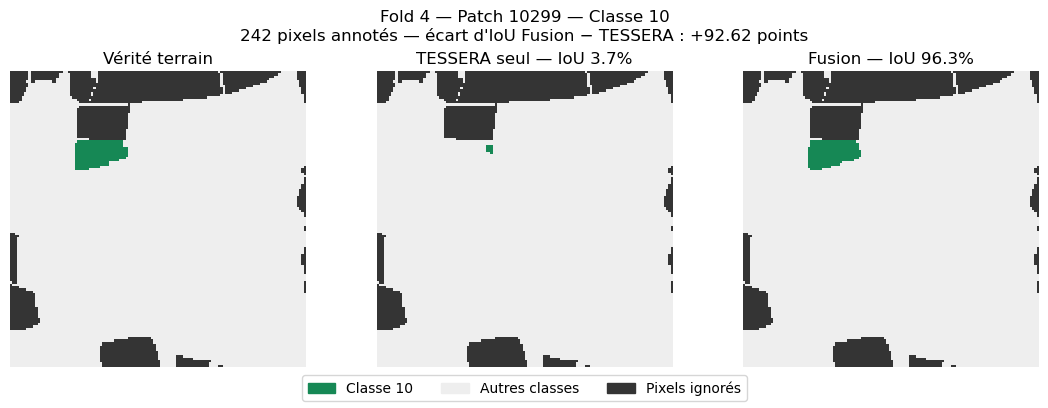

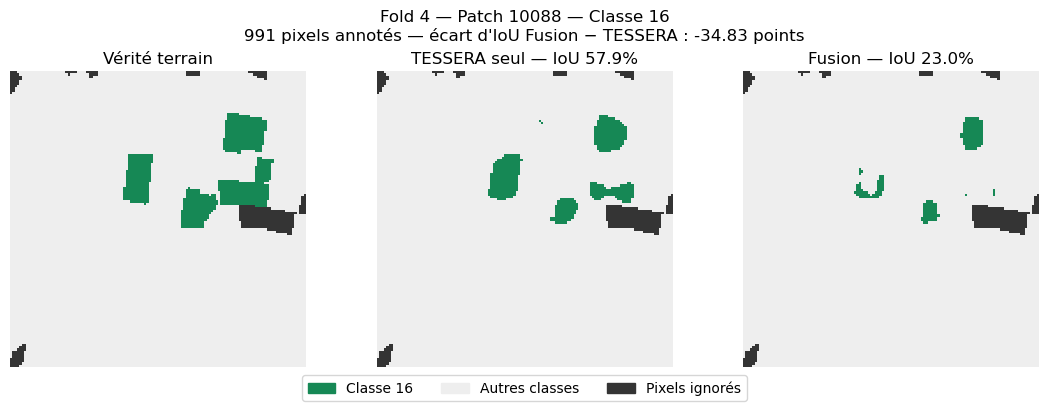

In [16]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Chercher un exemple d'amélioration et un exemple de dégradation.
directions = {10: 1, 16: -1}
examples = {}
min_pixels = 128

with torch.inference_mode():
    for batch in val_loader:
        target = batch["target"].to(eval_device, dtype=torch.long)
        valid = batch["valid"].to(eval_device, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < num_classes)

        inputs = {}
        for name, (mean, std) in stats_by_input.items():
            values = batch[name].to(eval_device, dtype=torch.float32)
            inputs[name] = ((values - mean) / std).masked_fill(~valid[:, None], 0)

        predictions = {
            name: net(inputs["image"], inputs["tessera"]).argmax(dim=1)
            for name, net in models.items()
        }

        for i, patch_id in enumerate(batch["patch_id"]):
            mask = keep[i]

            for cls, direction in directions.items():
                truth = (target[i] == cls) & mask
                support = int(truth.sum().item())
                if support < min_pixels:
                    continue

                predicted = {
                    name: (prediction[i] == cls) & mask
                    for name, prediction in predictions.items()
                }
                iou = {
                    name: (truth & pred).sum().item() / (truth | pred).sum().item()
                    for name, pred in predicted.items()
                }
                delta = iou["fusion"] - iou["tessera"]
                score = direction * delta
                previous = examples.get(cls)

                if score > 0 and (previous is None or score > previous["score"]):
                    examples[cls] = {
                        "patch_id": int(patch_id),
                        "support": support,
                        "score": score,
                        "delta": delta,
                        "iou": iou,
                        "valid": mask.cpu().numpy(),
                        "truth": truth.cpu().numpy(),
                        "predicted": {
                            name: pred.cpu().numpy() for name, pred in predicted.items()
                        },
                    }

# Afficher les pixels de la classe étudiée en vert.
cmap = ListedColormap(["#eeeeee", "#168855", "#343434"])

for cls in directions:
    if cls not in examples:
        print(f"Classe {cls} — aucun exemple correspondant aux critères.")
        continue

    example = examples[cls]
    fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")
    panels = [
        ("Vérité terrain", example["truth"]),
        (f"TESSERA seul — IoU {example['iou']['tessera']:.1%}",
         example["predicted"]["tessera"]),
        (f"Fusion — IoU {example['iou']['fusion']:.1%}",
         example["predicted"]["fusion"]),
    ]

    for ax, (title, class_mask) in zip(axes, panels):
        panel = np.where(example["valid"], class_mask.astype(np.uint8), 2)
        ax.imshow(panel, cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(
        f"Fold 4 — Patch {example['patch_id']} — Classe {cls}\n"
        f"{example['support']} pixels annotés — "
        f"écart d'IoU Fusion − TESSERA : {100 * example['delta']:+.2f} points"
    )
    fig.legend(
        handles=[
            Patch(color="#168855", label=f"Classe {cls}"),
            Patch(color="#eeeeee", label="Autres classes"),
            Patch(color="#343434", label="Pixels ignorés"),
        ],
        loc="outside lower center",
        ncol=3,
    )
    plt.show()

## Analyse qualitative des prédictions sur le Fold 4

De gauche à droite, la figure présente les annotations de référence, la prédiction de TESSERA seul et celle de la fusion Sentinel‑2 + TESSERA. En vert figure la classe étudiée. Les pixels en gris foncé sont ignorés lors de l’évaluation.

- **Classe 10, patch 10299.** TESSERA seul manque presque toute la parcelle annotée. La prédiction de la fusion recouvre presque entièrement la zone de référence. L’IoU passe de **3,7 % à 96,3 %**, soit un gain de **92,62 points de pourcentage**.
- **Classe 16, patch 10088.** TESSERA seul détecte plusieurs zones annotées. Avec la fusion, certaines zones prédites deviennent plus petites ou disparaissent. L’IoU passe de **57,9 % à 23,0 %**, soit une baisse de **34,83 points de pourcentage**.

Ces deux exemples ont été choisis pour illustrer un gain et une perte. Sur l’ensemble des **475 patchs de validation**, la fusion améliore l’IoU de **10 classes** et le réduit pour **9 classes**. Ces variations se compensent presque dans la moyenne, avec un mIoU de **62,33 %** pour la fusion et de **62,42 %** pour TESSERA seul.

Entraînement : 1431 patches
Validation : 475 patches
image : (2, 30, 128, 128)
tessera : (2, 128, 128, 128)
target : (2, 128, 128)


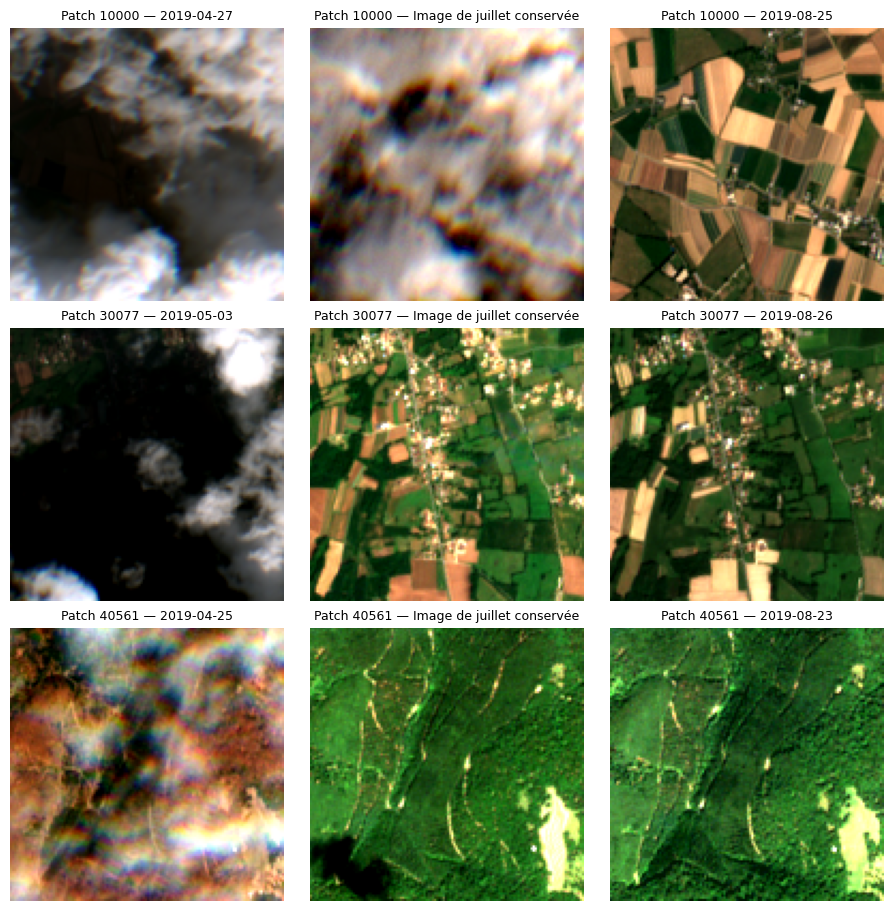

In [17]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader


class PastisThreeDateDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows.reset_index(drop=True).copy()
        self.base = PastisFusionDataset(self.rows)

        self.side_dates = []
        for pid in self.rows["patch_id"]:
            dates = pd.to_datetime(
                [str(value) for value in dates_s2[str(int(pid))]],
                format="%Y%m%d",
            )
            indices = tuple(
                int(np.argmin(np.abs((dates - date).days)))
                for date in (pd.Timestamp("2019-05-01"), pd.Timestamp("2019-08-25"))
            )
            self.side_dates.append((dates, indices))

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        sample = self.base[index]
        row = self.rows.iloc[index]
        dates, (spring_idx, late_idx) = self.side_dates[index]
        series = np.load(row["image_path"], mmap_mode="r")

        if len(dates) != series.shape[0]:
            raise ValueError(f"Nombre de dates incohérent pour le patch {sample['patch_id']}.")

        spring = torch.from_numpy(series[spring_idx].astype(np.float32))
        late = torch.from_numpy(series[late_idx].astype(np.float32))
        image = torch.cat((spring, sample["image"], late), dim=0)

        # Conserver le masque existant et vérifier les deux nouvelles images.
        valid = sample["valid"].bool().reshape_as(sample["target"])
        valid = valid & torch.isfinite(image).all(dim=0)

        return {
            **sample,
            "image": image.masked_fill(~valid.unsqueeze(0), 0),
            "tessera": sample["tessera"].masked_fill(~valid.unsqueeze(0), 0),
            "target": sample["target"].masked_fill(~valid, 19),
            "valid": valid,
        }


train_three = PastisThreeDateDataset(train_rows)
val_three = PastisThreeDateDataset(val_rows)

train_loader_three = DataLoader(
    train_three, batch_size=2, shuffle=True, num_workers=0
)
val_loader_three = DataLoader(
    val_three, batch_size=2, shuffle=False, num_workers=0
)

batch = next(iter(val_loader_three))
print(f"Entraînement : {len(train_three)} patches")
print(f"Validation : {len(val_three)} patches")
for name in ("image", "tessera", "target"):
    print(f"{name} : {tuple(batch[name].shape)}")

# Vérifier visuellement trois patches du jeu d'entraînement.
preview_indices = (0, len(train_three) // 2, len(train_three) - 1)
fig, axes = plt.subplots(3, 3, figsize=(9, 9), layout="constrained")

for row_axes, index in zip(axes, preview_indices):
    sample = train_three[index]
    dates, (spring_idx, late_idx) = train_three.side_dates[index]
    frames = sample["image"].reshape(3, 10, 128, 128).numpy()
    titles = (
        f"{dates[spring_idx]:%Y-%m-%d}",
        "Image de juillet conservée",
        f"{dates[late_idx]:%Y-%m-%d}",
    )

    for ax, frame, title in zip(row_axes, frames, titles):
        rgb = np.moveaxis(frame[[2, 1, 0]], 0, -1)
        lo, hi = np.percentile(rgb, [2, 98])
        ax.imshow(np.clip((rgb - lo) / max(hi - lo, 1e-6), 0, 1))
        ax.set_title(f"Patch {sample['patch_id']} — {title}", fontsize=9)
        ax.axis("off")

plt.show()

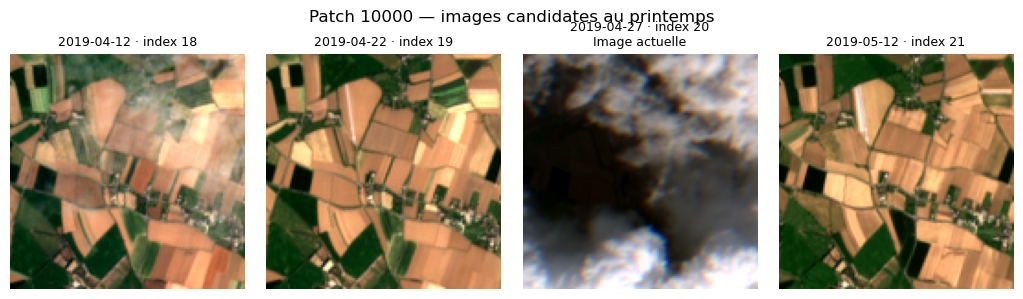

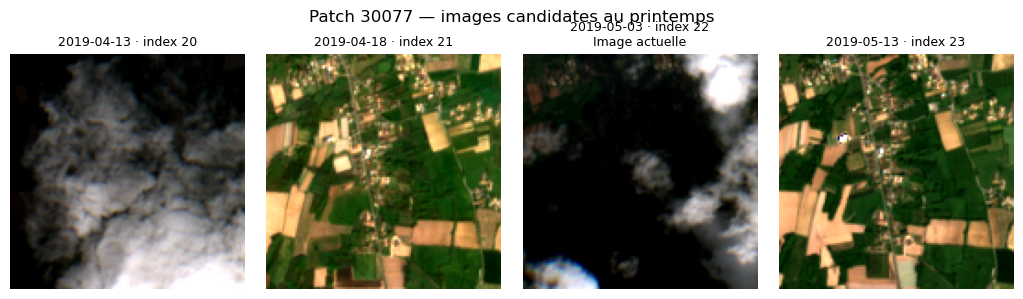

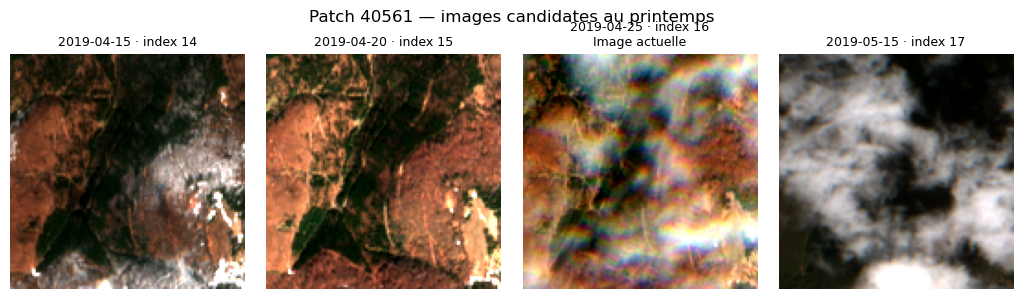

In [18]:
spring_target = pd.Timestamp("2019-05-01")

for index in preview_indices:
    row = train_three.rows.iloc[index]
    dates, (selected_idx, _) = train_three.side_dates[index]
    series = np.load(row["image_path"], mmap_mode="r")
    candidates = np.flatnonzero(np.abs((dates - spring_target).days) <= 20)

    if len(candidates) == 0:
        print(f"Patch {row['patch_id']} — aucune image dans la fenêtre.")
        continue

    fig, axes = plt.subplots(
        1, len(candidates), figsize=(2.6 * len(candidates), 3), squeeze=False
    )

    for ax, i in zip(axes[0], candidates):
        rgb = np.moveaxis(series[i, [2, 1, 0]].astype(np.float32), 0, -1)
        lo, hi = np.percentile(rgb, [2, 98])
        ax.imshow(np.clip((rgb - lo) / max(hi - lo, 1e-6), 0, 1))
        marker = "\nImage actuelle" if i == selected_idx else ""
        ax.set_title(f"{dates[i]:%Y-%m-%d} · index {i}{marker}", fontsize=9)
        ax.axis("off")

    fig.suptitle(f"Patch {row['patch_id']} — images candidates au printemps")
    fig.tight_layout()
    plt.show()

In [19]:
import pandas as pd
import torch
from IPython.display import display

# Réutiliser le modèle Fusion à 10 bandes et sa normalisation d'origine.
assert len(val_loader_three.dataset) == 475, "Le Fold 4 doit contenir 475 patches."
fusion_eval.eval()
tessera_eval.eval()

seasons = ("Printemps", "Juillet", "Fin août")
methods = (*seasons, "Moyenne des trois", "TESSERA seul")
n_classes = 19

confusions = {
    name: torch.zeros(
        (n_classes, n_classes), dtype=torch.int64, device=eval_device
    )
    for name in methods
}

with torch.inference_mode():
    for step, batch in enumerate(val_loader_three, start=1):
        target = batch["target"].to(eval_device, dtype=torch.long)
        valid = batch["valid"].to(eval_device, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < n_classes)

        # Les trois dates utilisent le même embedding annuel pour chaque patch.
        image_mean, image_std = stats_by_input["image"]
        tessera_mean, tessera_std = stats_by_input["tessera"]

        frames = batch["image"].to(eval_device, dtype=torch.float32)
        frames = frames.split(10, dim=1)
        assert len(frames) == 3, "Trois images Sentinel-2 sont attendues."

        tessera = batch["tessera"].to(eval_device, dtype=torch.float32)
        tessera = ((tessera - tessera_mean) / tessera_std).masked_fill(
            ~valid[:, None], 0
        )

        probabilities = []
        predictions = {}

        for name, frame in zip(seasons, frames):
            image = ((frame - image_mean) / image_std).masked_fill(
                ~valid[:, None], 0
            )
            proba = fusion_eval(image, tessera).softmax(dim=1)
            probabilities.append(proba)
            predictions[name] = proba.argmax(dim=1)

        predictions["Moyenne des trois"] = (
            torch.stack(probabilities).mean(dim=0).argmax(dim=1)
        )

        # Le modèle TESSERA seul conserve sa signature à deux entrées.
        predictions["TESSERA seul"] = tessera_eval(
            torch.zeros_like(frames[0]), tessera
        ).argmax(dim=1)

        # Comparer toutes les méthodes sur les mêmes pixels annotés.
        for name, prediction in predictions.items():
            indices = target[keep] * n_classes + prediction[keep]
            confusions[name] += torch.bincount(
                indices, minlength=n_classes ** 2
            ).reshape(n_classes, n_classes)

        if step % 50 == 0 or step == len(val_loader_three):
            print(f"Validation : {step}/{len(val_loader_three)} lots")

rows = []
for name, cm in confusions.items():
    correct = cm.diagonal()
    union = cm.sum(dim=0) + cm.sum(dim=1) - correct
    present = union > 0
    miou = (correct[present] / union[present]).mean().item()
    accuracy = (correct.sum() / cm.sum()).item()

    rows.append({
        "Méthode": name,
        "mIoU (%)": 100 * miou,
        "Exactitude pixel (%)": 100 * accuracy,
    })

results_dates = pd.DataFrame(rows)
july_miou = results_dates.loc[
    results_dates["Méthode"] == "Juillet", "mIoU (%)"
].iloc[0]
results_dates["Écart vs juillet (points)"] = results_dates["mIoU (%)"] - july_miou
display(results_dates.round(2))

Validation : 50/238 lots
Validation : 100/238 lots
Validation : 150/238 lots
Validation : 200/238 lots
Validation : 238/238 lots


,Méthode,mIoU (%),Exactitude pixel (%),Écart vs juillet (points)
0,Printemps,61.76,83.92,-0.57
1,Juillet,62.33,84.04,0.00
2,Fin août,61.39,83.81,-0.94
3,Moyenne des trois,62.30,84.06,-0.03
4,TESSERA seul,62.42,83.90,0.09


In [20]:
from datetime import datetime
from pathlib import Path

import pandas as pd
import torch
import torch.nn.functional as F

# Réutiliser les mêmes jeux de données et la normalisation d'origine.
assert len(train_loader_three.dataset) == 1431
assert len(val_loader_three.dataset) == 475

device_dates = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

model_dates = FusionModel().to(device_dates)
optimizer_dates = torch.optim.AdamW(model_dates.parameters(), lr=1e-3)

mean_image, std_image = (
    value.to(device_dates) for value in stats_by_input["image"]
)
mean_tessera, std_tessera = (
    value.to(device_dates) for value in stats_by_input["tessera"]
)

results_root = Path(r"G:\Vmi\project\m2_image_results")
stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
out_dates = results_root / f"fusion_dates_aleatoires_full_{stamp}"
out_dates.mkdir(parents=True)

n_classes = 19
n_epochs = 20
best_miou = -1.0
history_dates = []

print(f"Appareil : {device_dates}")
print(f"Résultats : {out_dates}")


def prepare_dates_batch(batch):
    target = batch["target"].to(device_dates, dtype=torch.long)
    valid = batch["valid"].to(device_dates, dtype=torch.bool).reshape_as(target)
    keep = valid & (target >= 0) & (target < n_classes)
    target = target.masked_fill(~keep, 19)

    images = batch["image"].to(device_dates, dtype=torch.float32)
    assert images.shape[1] == 30, "Trois dates de dix bandes sont attendues."
    frames = images.unflatten(1, (3, 10))

    tessera = batch["tessera"].to(device_dates, dtype=torch.float32)
    tessera = ((tessera - mean_tessera) / std_tessera).masked_fill(
        ~valid[:, None], 0
    )
    return frames, tessera, target, valid


def normalize_date(frame, valid):
    return ((frame - mean_image) / std_image).masked_fill(~valid[:, None], 0)


for epoch in range(1, n_epochs + 1):
    model_dates.train()
    train_loss_sum = 0.0
    train_pixels = 0
    print(f"\nÉpoque {epoch}/{n_epochs}", flush=True)

    for step, batch in enumerate(train_loader_three, start=1):
        frames, tessera, target, valid = prepare_dates_batch(batch)
        count = int((target != 19).sum().item())

        if count:
            # Tirer indépendamment une date pour chaque patch du lot.
            batch_size = frames.shape[0]
            patches = torch.arange(batch_size, device=device_dates)
            chosen_dates = torch.randint(3, (batch_size,), device=device_dates)
            image = normalize_date(frames[patches, chosen_dates], valid)

            optimizer_dates.zero_grad(set_to_none=True)
            logits = model_dates(image, tessera)
            loss = F.cross_entropy(logits, target, ignore_index=19)
            loss.backward()
            optimizer_dates.step()

            train_loss_sum += loss.item() * count
            train_pixels += count

        if step % 100 == 0 or step == len(train_loader_three):
            print(f"  Entraînement : {step}/{len(train_loader_three)} lots", flush=True)

    model_dates.eval()
    cm = torch.zeros((n_classes, n_classes), dtype=torch.int64, device=device_dates)

    with torch.inference_mode():
        for batch in val_loader_three:
            frames, tessera, target, valid = prepare_dates_batch(batch)

            # Prédire séparément les trois dates et moyenner leurs probabilités.
            probabilities = [
                model_dates(normalize_date(frame, valid), tessera).softmax(dim=1)
                for frame in frames.unbind(dim=1)
            ]
            prediction = torch.stack(probabilities).mean(dim=0).argmax(dim=1)

            keep = target != 19
            indices = target[keep] * n_classes + prediction[keep]
            cm += torch.bincount(indices, minlength=n_classes ** 2).reshape_as(cm)

    correct = cm.diag()
    union = cm.sum(dim=0) + cm.sum(dim=1) - correct
    present = union > 0
    val_miou = (correct[present] / union[present]).mean().item()
    val_accuracy = (correct.sum() / cm.sum()).item()
    train_loss = train_loss_sum / train_pixels

    history_dates.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_miou": val_miou,
        "val_accuracy": val_accuracy,
    })
    pd.DataFrame(history_dates).to_csv(out_dates / "history.csv", index=False)

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model_dates.state_dict(),
        "optimizer_state_dict": optimizer_dates.state_dict(),
        "val_miou": val_miou,
    }
    torch.save(checkpoint, out_dates / "last.pt")
    if val_miou > best_miou:
        best_miou = val_miou
        torch.save(checkpoint, out_dates / "best.pt")

    print(
        f"Train loss : {train_loss:.4f} | "
        f"Val mIoU : {val_miou:.2%} | Val accuracy : {val_accuracy:.2%}",
        flush=True,
    )

print(f"\nMeilleur mIoU : {best_miou:.2%}")
print(f"Checkpoint : {out_dates / 'best.pt'}")

Appareil : cuda
Résultats : G:\Vmi\project\m2_image_results\fusion_dates_aleatoires_full_20261114_225645_740308

Époque 1/20
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
Train loss : 0.9366 | Val mIoU : 37.61% | Val accuracy : 79.05%

Époque 2/20
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
Train loss : 0.6175 | Val mIoU : 47.48% | Val accuracy : 80.53%

Époque 3/20
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
T

## Fusion Sentinel-2 + TESSERA avec trois dates

Pour chaque patch d’entraînement, une image Sentinel-2 est tirée au hasard à chaque époque parmi trois dates correspondant au printemps, au début de juillet et à la fin d’août. Les 10 bandes de l’image choisie sont utilisées avec l’embedding TESSERA du même patch. Le modèle est entraîné pendant 20 époques sur les 1 431 patchs des folds 1 à 3.

Sur les 475 patchs de validation du fold 4, le modèle prédit une carte de probabilités pour chaque date. Pour chaque pixel, les probabilités des trois prédictions sont moyennées, puis la classe la plus probable est retenue.

| Méthode | mIoU de validation | Exactitude par pixel au même checkpoint |
|---|---:|---:|
| TESSERA seul | 62,42 % | 83,90 % |
| Fusion entraînée et évaluée avec l’image de juillet | 62,33 % | 84,04 % |
| Fusion entraînée avec l’image de juillet, puis évaluée avec la moyenne des trois dates | 62,30 % | 84,06 % |
| Fusion entraînée avec tirage aléatoire parmi trois dates, puis évaluée avec leur moyenne | **62,99 %** | 83,77 % |

Le meilleur checkpoint du modèle entraîné avec trois dates est obtenu à la **19e époque**. Son mIoU dépasse de **0,69 point** celui du modèle entraîné sur juillet lorsque les deux modèles sont évalués avec la moyenne des mêmes trois dates. Le gain est de **0,57 point** par rapport à TESSERA seul, avec une exactitude par pixel légèrement inférieure. Ce gain observé en validation reste à confirmer sur plusieurs entraînements.

La prochaine expérience utilisera ce même checkpoint pour comparer les moyennes calculées sur 3 dates, 10 dates et toutes les dates disponibles, sur les mêmes pixels de validation.

In [21]:
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset


class PastisTenDateDataset(Dataset):
    def __init__(self, base_three, training, seed=42):
        self.base = base_three
        self.training = training
        self.rng = np.random.default_rng(seed)
        self.selections = []

        for index, row in base_three.rows.iterrows():
            pid = int(row["patch_id"])
            dates, (spring_idx, late_idx) = base_three.side_dates[index]
            july_target = pd.Timestamp(
                "2019-07-02" if pid == 30708 else "2019-07-06"
            )
            july_idx = int(np.argmin(np.abs((dates - july_target).days)))

            # Garder les trois dates de référence et combler les grands intervalles.
            original = (spring_idx, july_idx, late_idx)
            if len(set(original)) != 3 or len(dates) < 10:
                raise ValueError(f"Dix dates distinctes requises pour le patch {pid}.")

            offsets = np.asarray((dates - dates.min()).days)
            selected = list(original)
            remaining = set(range(len(dates))) - set(original)
            while len(selected) < 10:
                candidate = max(
                    sorted(remaining),
                    key=lambda j: min(abs(offsets[j] - offsets[k]) for k in selected),
                )
                selected.append(candidate)
                remaining.remove(candidate)

            self.selections.append((len(dates), original, selected))

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        sample = self.base[index]
        row = self.base.rows.iloc[index]
        n_dates, original, selected = self.selections[index]
        series = np.load(row["image_path"], mmap_mode="r")
        if series.shape != (n_dates, 10, 128, 128):
            raise ValueError(f"Série Sentinel-2 incohérente : {sample['patch_id']}")

        # Réutiliser exactement les trois images de l'expérience précédente.
        original_frames = dict(zip(original, sample["image"].reshape(3, 10, 128, 128)))
        indices = [selected[self.rng.integers(10)]] if self.training else selected
        frames = torch.stack([
            original_frames[j] if j in original_frames
            else torch.from_numpy(series[j].astype(np.float32))
            for j in indices
        ])

        return {
            "frames": frames,
            "tessera": sample["tessera"],
            "target": sample["target"],
            "valid": sample["valid"],
        }


torch.manual_seed(42)
device10 = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train10 = PastisTenDateDataset(train_three, training=True)
val10 = PastisTenDateDataset(val_three, training=False)
assert (len(train10), len(val10)) == (1431, 475)

train_loader10 = DataLoader(train10, batch_size=2, shuffle=True, num_workers=0)
val_loader10 = DataLoader(val10, batch_size=2, shuffle=False, num_workers=0)

model10 = FusionModel().to(device10)
optimizer10 = torch.optim.AdamW(model10.parameters(), lr=1e-3)
stats10 = {
    name: tuple(value.to(device10) for value in pair)
    for name, pair in stats_by_input.items()
}

out10 = Path(r"G:\Vmi\project\m2_image_results") / (
    "fusion_10dates_full_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
out10.mkdir(parents=True)

print(f"Appareil : {device10} | Train : {len(train10)} | Validation : {len(val10)}")
print(f"Résultats : {out10}")


def prepare_batch10(batch):
    target = batch["target"].to(device10, dtype=torch.long)
    valid = batch["valid"].to(device10, dtype=torch.bool).reshape_as(target)
    keep = valid & (target >= 0) & (target < 19)
    target = target.masked_fill(~keep, 19)

    frames = batch["frames"].to(device10, dtype=torch.float32)
    tessera = batch["tessera"].to(device10, dtype=torch.float32)
    mean, std = stats10["tessera"]
    tessera = ((tessera - mean) / std).masked_fill(~valid[:, None], 0)
    return frames, tessera, target, valid


def normalize_image10(frame, valid):
    # Neutraliser les entrées non finies sans changer le masque d'évaluation.
    frame_valid = valid & torch.isfinite(frame).all(dim=1)
    mean, std = stats10["image"]
    return ((frame - mean) / std).masked_fill(~frame_valid[:, None], 0)


best_miou10 = -1.0
history10 = []

for epoch in range(1, 21):
    print(f"\nÉpoque {epoch}/20", flush=True)
    model10.train()
    loss_sum = 0.0
    pixel_count = 0

    for step, batch in enumerate(train_loader10, start=1):
        frames, tessera, target, valid = prepare_batch10(batch)
        count = int((target != 19).sum().item())

        if count:
            image = normalize_image10(frames[:, 0], valid)
            optimizer10.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model10(image, tessera), target, ignore_index=19)
            loss.backward()
            optimizer10.step()

            loss_sum += loss.item() * count
            pixel_count += count

        if step % 100 == 0 or step == len(train_loader10):
            print(f"  Entraînement : {step}/{len(train_loader10)} lots", flush=True)

    model10.eval()
    cm = torch.zeros((19, 19), dtype=torch.int64, device=device10)

    with torch.inference_mode():
        for step, batch in enumerate(val_loader10, start=1):
            frames, tessera, target, valid = prepare_batch10(batch)

            # La somme et la moyenne donnent la même classe par argmax.
            probability_sum = torch.zeros(
                (target.shape[0], 19, *target.shape[-2:]), device=device10
            )
            for frame in frames.unbind(dim=1):
                image = normalize_image10(frame, valid)
                probability_sum += model10(image, tessera).float().softmax(dim=1)

            prediction = probability_sum.argmax(dim=1)
            keep = target != 19
            codes = target[keep] * 19 + prediction[keep]
            cm += torch.bincount(codes, minlength=19 ** 2).reshape(19, 19)

            if step % 50 == 0 or step == len(val_loader10):
                print(f"  Validation : {step}/{len(val_loader10)} lots", flush=True)

    correct = cm.diag()
    union = cm.sum(dim=0) + cm.sum(dim=1) - correct
    present = union > 0
    miou = (correct[present] / union[present]).mean().item()
    accuracy = (correct.sum() / cm.sum()).item()
    train_loss = loss_sum / pixel_count

    history10.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_miou": miou,
        "val_accuracy": accuracy,
    })
    pd.DataFrame(history10).to_csv(out10 / "history.csv", index=False)

    checkpoint10 = {
        "epoch": epoch,
        "model_state_dict": model10.state_dict(),
        "optimizer_state_dict": optimizer10.state_dict(),
        "val_miou": miou,
        "val_accuracy": accuracy,
    }
    torch.save(checkpoint10, out10 / "last.pt")
    if miou > best_miou10:
        best_miou10 = miou
        torch.save(checkpoint10, out10 / "best.pt")

    print(
        f"Train loss Ioss : {train_loss:.4f} | "
        f"Val mIoU : {miou:.2%} | Val accuracy : {accuracy:.2%}",
        flush=True,
    )

best_row10 = max(history10, key=lambda row: row["val_miou"])
print(f"\nMeilleure époque : {best_row10['epoch']}")
print(f"Meilleur mIoU : {best_miou10:.2%}")
print(f"Checkpoint : {out10 / 'best.pt'}")

Appareil : cuda | Train : 1431 | Validation : 475
Résultats : G:\Vmi\project\m2_image_results\fusion_10dates_full_20261115_012540_510859

Époque 1/20
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/238 lots
  Validation : 100/238 lots
  Validation : 150/238 lots
  Validation : 200/238 lots
  Validation : 238/238 lots
Train loss Ioss : 0.9292 | Val mIoU : 38.10% | Val accuracy : 78.94%

Époque 2/20
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/238 lots
  Validation : 100/238 lots
  Validation : 150/238 lots
  Validation : 200/238 lots
  Validation : 238/238 lots
Train loss

## 20

In [25]:
from datetime import datetime, timedelta
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from torch.utils.data import DataLoader, Dataset


class PastisAllDatesDataset(Dataset):
    def __init__(self, base_three, training, seed=42):
        self.base = base_three
        self.training = training
        self.epoch = 0
        self.counts = [len(dates) for dates, _ in base_three.side_dates]

        if not self.counts or min(self.counts) < 1:
            raise ValueError("Chaque patch doit avoir au moins une date Sentinel-2.")

        rng = np.random.default_rng(seed)
        self.orders = [rng.permutation(count) for count in self.counts]

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        # Reprendre le masque commun aux expériences précédentes.
        sample = self.base[index]
        row = self.base.rows.iloc[index]
        n_dates = self.counts[index]

        series = np.load(row["image_path"], mmap_mode="r")
        if series.shape != (n_dates, 10, 128, 128):
            raise ValueError(f"Série Sentinel-2 incohérente : patch {sample['patch_id']}")

        if self.training:
            order = self.orders[index]
            date_index = int(order[self.epoch % n_dates])
            frames = series[date_index:date_index + 1].astype(np.float32)
        else:
            frames = series.astype(np.float32)

        return {
            "frames": torch.from_numpy(frames),
            "tessera": sample["tessera"],
            "target": sample["target"],
            "valid": sample["valid"],
        }


def duration(seconds):
    return str(timedelta(seconds=round(seconds)))


def train_all_dates():
    torch.manual_seed(42)
    device_all = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = 19
    ignore_index = 19
    validation_chunk = 4

    train_data = PastisAllDatesDataset(train_three, training=True)
    val_data = PastisAllDatesDataset(val_three, training=False)
    assert (len(train_data), len(val_data)) == (1431, 475)

    train_loader_all = DataLoader(
        train_data, batch_size=2, shuffle=True, num_workers=0
    )
    # Les patchs peuvent avoir des nombres de dates différents.
    val_loader_all = DataLoader(
        val_data, batch_size=1, shuffle=False, num_workers=0
    )

    epochs = max(train_data.counts)
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    out_all = Path(r"G:\Vmi\project\m2_image_results") / f"fusion_all_dates_full_{stamp}"
    out_all.mkdir(parents=True)

    model_all = FusionModel().to(device_all)
    optimizer_all = torch.optim.AdamW(model_all.parameters(), lr=1e-3)

    image_mean, image_std = (
        value.to(device_all) for value in stats_by_input["image"]
    )
    tessera_mean, tessera_std = (
        value.to(device_all) for value in stats_by_input["tessera"]
    )

    print(f"Appareil : {device_all}")
    print(f"Train : {len(train_data)} patches | Validation : {len(val_data)} patches")
    print(f"Dates par patch d'entraînement : {min(train_data.counts)}–{epochs}")
    print(f"Époques : {epochs} | Lots d'entraînement par époque : {len(train_loader_all)}")
    print(f"Résultats : {out_all}", flush=True)

    def prepare_batch(batch):
        target = batch["target"].to(device_all, dtype=torch.long)
        valid = batch["valid"].to(device_all, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < num_classes)
        target = target.masked_fill(~keep, ignore_index)

        tessera = batch["tessera"].to(device_all, dtype=torch.float32)
        tessera = ((tessera - tessera_mean) / tessera_std).masked_fill(
            ~valid[:, None], 0
        )
        return tessera, target, valid

    def normalize_frame(frames, valid):
        frames = frames.to(device_all, dtype=torch.float32)
        frame_valid = valid & torch.isfinite(frames).all(dim=1)
        return ((frames - image_mean) / image_std).masked_fill(
            ~frame_valid[:, None], 0
        )

    history = []
    best_all = -1.0
    best_20 = -1.0
    run_start = perf_counter()

    for epoch in range(1, epochs + 1):
        epoch_start = perf_counter()
        train_data.epoch = epoch - 1
        model_all.train()
        loss_sum = 0.0
        pixel_count = 0
        print(f"\nÉpoque {epoch}/{epochs}", flush=True)

        for step, batch in enumerate(train_loader_all, start=1):
            tessera, target, valid = prepare_batch(batch)
            count = int((target != ignore_index).sum().item())

            if count:
                image = normalize_frame(batch["frames"][:, 0], valid)
                optimizer_all.zero_grad(set_to_none=True)
                logits = model_all(image, tessera)
                loss = F.cross_entropy(logits, target, ignore_index=ignore_index)
                loss.backward()
                optimizer_all.step()

                loss_sum += loss.item() * count
                pixel_count += count

            if step % 100 == 0 or step == len(train_loader_all):
                print(f"  Entraînement : {step}/{len(train_loader_all)} lots", flush=True)

        if not pixel_count:
            raise ValueError("Aucun pixel annoté valide pour l'entraînement.")

        train_seconds = perf_counter() - epoch_start
        validation_start = perf_counter()
        model_all.eval()
        cm = torch.zeros(
            (num_classes, num_classes), dtype=torch.int64, device=device_all
        )

        with torch.inference_mode():
            for step, batch in enumerate(val_loader_all, start=1):
                tessera, target, valid = prepare_batch(batch)
                probability_sum = torch.zeros(
                    (num_classes, *target.shape[-2:]),
                    dtype=torch.float32,
                    device=device_all,
                )

                # Traiter quelques dates à la fois pour limiter la mémoire GPU.
                for chunk in batch["frames"][0].split(validation_chunk, dim=0):
                    images = normalize_frame(chunk, valid)
                    embeddings = tessera.expand(len(chunk), -1, -1, -1)
                    probabilities = model_all(images, embeddings).float().softmax(dim=1)
                    probability_sum += probabilities.sum(dim=0)

                # Diviser par le nombre de dates ne change pas la classe prédite.
                prediction = probability_sum.argmax(dim=0)
                keep = target[0] != ignore_index
                codes = target[0][keep] * num_classes + prediction[keep]
                cm += torch.bincount(
                    codes, minlength=num_classes ** 2
                ).reshape_as(cm)

                if step % 50 == 0 or step == len(val_loader_all):
                    print(f"  Validation : {step}/{len(val_loader_all)} patches", flush=True)

        cm = cm.cpu()
        val_seconds = perf_counter() - validation_start
        correct = cm.diag()
        union = cm.sum(0) + cm.sum(1) - correct
        present = union > 0
        if not present.any().item():
            raise ValueError("Aucun pixel annoté valide pour la validation.")

        miou = (correct[present] / union[present]).mean().item()
        accuracy = (correct.sum() / cm.sum()).item()
        train_loss = loss_sum / pixel_count

        checkpoint = {
            "epoch": epoch,
            "model_state_dict": model_all.state_dict(),
            "optimizer_state_dict": optimizer_all.state_dict(),
            "val_miou": miou,
            "val_accuracy": accuracy,
        }
        torch.save(checkpoint, out_all / "last.pt")

        if miou > best_all:
            best_all = miou
            torch.save(checkpoint, out_all / "best.pt")

        if epoch <= 20 and miou > best_20:
            best_20 = miou
            torch.save(checkpoint, out_all / "best_20epochs.pt")

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_miou": miou,
            "val_accuracy": accuracy,
            "train_seconds": round(train_seconds, 1),
            "val_seconds": round(val_seconds, 1),
            "epoch_seconds": round(perf_counter() - epoch_start, 1),
        })
        pd.DataFrame(history).to_csv(out_all / "history.csv", index=False)

        elapsed = perf_counter() - run_start
        remaining = (elapsed / epoch) * (epochs - epoch)

        print(
            f"Train loss : {train_loss:.4f} | "
            f"Val mIoU : {miou:.2%} | Val accuracy : {accuracy:.2%}",
            flush=True,
        )
        print(
            f"  Train : {duration(train_seconds)} | Val : {duration(val_seconds)} | "
            f"Écoulé : {duration(elapsed)} | Reste estimé : {duration(remaining)}",
            flush=True,
        )

    history_df = pd.DataFrame(history)
    best_epoch = int(history_df.loc[history_df["val_miou"].idxmax(), "epoch"])
    print(f"\nDurée totale : {duration(perf_counter() - run_start)}")
    print(f"Meilleur mIoU jusqu'à l'époque 20 : {best_20:.2%}")
    print(f"Meilleur mIoU global : {best_all:.2%} (époque {best_epoch})")
    print(f"mIoU après couverture complète : {history_df.iloc[-1]['val_miou']:.2%}")
    print(f"Résultats : {out_all}")
    return out_all, history_df


out_all, history_all = train_all_dates()
display(history_all.sort_values("val_miou", ascending=False).head())

Appareil : cuda
Train : 1431 patches | Validation : 475 patches
Dates par patch d'entraînement : 38–61
Époques : 61 | Lots d'entraînement par époque : 716
Résultats : G:\Vmi\project\m2_image_results\fusion_all_dates_full_20261115_102016_403369

Époque 1/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/475 patches
  Validation : 100/475 patches
  Validation : 150/475 patches
  Validation : 200/475 patches
  Validation : 250/475 patches
  Validation : 300/475 patches
  Validation : 350/475 patches
  Validation : 400/475 patches
  Validation : 450/475 patches
  Validation : 475/475 patches
Train loss : 0.9482 | Val mIoU : 37.95% | Val accuracy : 78.71%
  Train : 0:02:55 | Val : 0:01:38 | Écoulé : 0:04:33 | Reste estimé : 4:33:15

Époque 2/61
  Entraînement : 100/716 lots
  Entraîn

,epoch,train_loss,val_miou,val_accuracy,train_seconds,val_seconds,epoch_seconds
58,59,0.372430,0.645524,0.840538,175.7,96.9,272.6
48,49,0.387939,0.642067,0.840766,194.4,98.5,293.0
57,58,0.378323,0.641522,0.842130,171.5,97.4,268.9
53,54,0.380101,0.641438,0.840550,169.6,97.5,267.1
39,40,0.402752,0.641328,0.840156,198.5,167.3,365.8


## ALL

In [26]:
from datetime import datetime, timedelta
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import torch
from IPython.display import display

root = Path(r"G:\Vmi\project\m2_image_results")

runs = {
    "1 date": "fusion_full_20261114_122121_139224",
    "3 dates": "fusion_dates_aleatoires_full_20261114_225645_740308",
    "10 dates": "fusion_10dates_full_20261115_012540_510859",
    "20 dates": "fusion_20dates_full_20261115_085835_429718",
    "Toutes les dates": "fusion_all_dates_full_20261115_102016_403369",
}

device_test = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_classes = 19
chunk_size = 4

# Reprendre les règles de sélection utilisées en validation.
test_three = PastisThreeDateDataset(test_rows)
test_ten = PastisTenDateDataset(test_three, training=False)
test_twenty = PastisTwentyDateDataset(test_ten, training=False)
assert len(test_three) == 493, "Le Fold 5 doit contenir 493 patches."

models_test = {}
for name, run in runs.items():
    path = root / run / "best.pt"
    if not path.is_file():
        raise FileNotFoundError(f"Checkpoint introuvable : {path}")

    # Charger uniquement les checkpoints de nos propres entraînements.
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    weights = checkpoint
    for key in ("model_state_dict", "model_state", "model", "state_dict"):
        if key in checkpoint:
            weights = checkpoint[key]
            break

    net = FusionModel()
    net.load_state_dict(weights, strict=True)
    models_test[name] = net.to(device_test).eval()
    print(f"{name} — checkpoint : époque {checkpoint.get('epoch', '?')}")

image_mean, image_std = (
    value.to(device_test) for value in stats_by_input["image"]
)
tessera_mean, tessera_std = (
    value.to(device_test) for value in stats_by_input["tessera"]
)

confusions_test = {
    name: torch.zeros(
        (n_classes, n_classes), dtype=torch.int64, device=device_test
    )
    for name in runs
}

start_time = perf_counter()
print(f"Appareil : {device_test} | Fold 5 : {len(test_three)} patches", flush=True)

with torch.inference_mode():
    for index in range(len(test_three)):
        sample = test_three[index]
        row = test_three.rows.iloc[index]
        n_dates, original, ten_indices = test_ten.selections[index]
        _, _, twenty_indices, _ = test_twenty.selections[index]

        series = np.load(row["image_path"], mmap_mode="r")
        if series.shape != (n_dates, 10, 128, 128):
            raise ValueError(f"Série Sentinel-2 incohérente : {sample['patch_id']}")

        date_groups = {
            "1 date": (original[1],),
            "3 dates": original,
            "10 dates": ten_indices,
            "20 dates": twenty_indices,
            "Toutes les dates": range(n_dates),
        }

        target = sample["target"].to(device_test, dtype=torch.long)
        valid = sample["valid"].to(device_test, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < n_classes)

        tessera = sample["tessera"].to(device_test, dtype=torch.float32)[None]
        tessera = ((tessera - tessera_mean) / tessera_std).masked_fill(
            ~valid[None, None], 0
        )

        # Réutiliser les trois scènes préparées par le dataset de référence.
        original_frames = dict(zip(
            original, sample["image"].reshape(3, 10, 128, 128)
        ))

        for name, indices in date_groups.items():
            probability_sum = torch.zeros(
                (n_classes, *target.shape),
                dtype=torch.float32,
                device=device_test,
            )

            for start in range(0, len(indices), chunk_size):
                chunk = indices[start:start + chunk_size]
                frames = torch.stack([
                    original_frames[j] if j in original_frames
                    else torch.from_numpy(series[j].astype(np.float32))
                    for j in chunk
                ]).to(device_test, dtype=torch.float32)

                frame_valid = valid[None] & torch.isfinite(frames).all(dim=1)
                frames = ((frames - image_mean) / image_std).masked_fill(
                    ~frame_valid[:, None], 0
                )

                embeddings = tessera.expand(len(chunk), -1, -1, -1)
                logits = models_test[name](frames, embeddings)
                probability_sum += logits.float().softmax(dim=1).sum(dim=0)

            # La somme et la moyenne donnent le même argmax pour ce patch.
            prediction = probability_sum.argmax(dim=0)
            codes = target[keep] * n_classes + prediction[keep]
            confusions_test[name] += torch.bincount(
                codes, minlength=n_classes ** 2
            ).reshape(n_classes, n_classes)

        done = index + 1
        if done % 25 == 0 or done == len(test_three):
            elapsed = perf_counter() - start_time
            remaining = elapsed / done * (len(test_three) - done)
            print(
                f"Test : {done}/{len(test_three)} patches | "
                f"Écoulé : {timedelta(seconds=round(elapsed))} | "
                f"Reste estimé : {timedelta(seconds=round(remaining))}",
                flush=True,
            )

summary = []
per_class = pd.DataFrame({"classe": np.arange(n_classes)})

for name, matrix in confusions_test.items():
    cm = matrix.cpu().numpy()
    correct = cm.diagonal()
    support = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    union = support + predicted - correct
    present = union > 0

    iou = np.full(n_classes, np.nan)
    iou[present] = correct[present] / union[present]
    f1 = 2 * correct[present] / (support + predicted)[present]

    summary.append({
        "Méthode": name,
        "mIoU test (%)": 100 * iou[present].mean(),
        "Macro-F1 test (%)": 100 * f1.mean(),
        "Exactitude pixel (%)": 100 * correct.sum() / cm.sum(),
    })
    per_class["pixels_reels"] = support
    per_class[name] = 100 * iou

results_test = pd.DataFrame(summary)
results_test["Écart vs 1 date (points)"] = (
    results_test["mIoU test (%)"] - results_test.loc[0, "mIoU test (%)"]
)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
out_test = root / f"comparaison_fusion_fold5_{stamp}"
out_test.mkdir(parents=True)
results_test.to_csv(out_test / "scores_test.csv", index=False)
per_class.to_csv(out_test / "iou_par_classe.csv", index=False)

display(results_test.round(2))
display(per_class.round(2))
print(f"Résultats : {out_test}")

1 date — checkpoint : époque 20
3 dates — checkpoint : époque 19
10 dates — checkpoint : époque 18
20 dates — checkpoint : époque 19
Toutes les dates — checkpoint : époque 59
Appareil : cuda | Fold 5 : 493 patches
Test : 25/493 patches | Écoulé : 0:00:06 | Reste estimé : 0:01:55
Test : 50/493 patches | Écoulé : 0:00:12 | Reste estimé : 0:01:47
Test : 75/493 patches | Écoulé : 0:00:18 | Reste estimé : 0:01:42
Test : 100/493 patches | Écoulé : 0:00:24 | Reste estimé : 0:01:36
Test : 125/493 patches | Écoulé : 0:00:31 | Reste estimé : 0:01:31
Test : 150/493 patches | Écoulé : 0:00:38 | Reste estimé : 0:01:28
Test : 175/493 patches | Écoulé : 0:00:45 | Reste estimé : 0:01:22
Test : 200/493 patches | Écoulé : 0:00:52 | Reste estimé : 0:01:16
Test : 225/493 patches | Écoulé : 0:00:59 | Reste estimé : 0:01:10
Test : 250/493 patches | Écoulé : 0:01:05 | Reste estimé : 0:01:04
Test : 275/493 patches | Écoulé : 0:01:12 | Reste estimé : 0:00:57
Test : 300/493 patches | Écoulé : 0:01:18 | Reste es

,Méthode,mIoU test (%),Macro-F1 test (%),Exactitude pixel (%),Écart vs 1 date (points)
0,1 date,61.11,74.15,83.26,0.00
1,3 dates,61.13,74.09,83.06,0.03
2,10 dates,61.09,74.10,83.22,-0.02
3,20 dates,61.95,74.85,83.21,0.84
4,Toutes les dates,62.73,75.52,83.51,1.62


,classe,pixels_reels,1 date,3 dates,10 dates,20 dates,Toutes les dates
0,0,3199771,74.93,74.72,74.87,74.67,74.88
1,1,1473825,64.95,63.86,65.02,64.40,64.73
2,2,577420,86.77,86.08,85.31,86.55,87.52
3,3,618126,85.32,84.99,85.55,85.13,86.09
4,4,171573,75.84,77.78,76.91,76.58,78.75
5,5,157375,87.50,88.80,87.41,88.22,89.21
6,6,55186,54.92,59.18,56.73,58.36,57.95
7,7,90899,66.19,66.10,67.71,69.06,67.62
8,8,219555,52.22,57.97,57.17,56.36,57.54
9,9,66953,81.49,84.01,84.15,85.57,84.18


Résultats : G:\Vmi\project\m2_image_results\comparaison_fusion_fold5_20261115_173153_191151


In [27]:
# Évaluer TESSERA seul sur les mêmes pixels du Fold 5.
tessera_eval = tessera_eval.to(device_test).eval()
cm_tessera = torch.zeros(
    (n_classes, n_classes), dtype=torch.int64, device=device_test
)

with torch.inference_mode():
    for index in range(len(test_three)):
        sample = test_three[index]
        target = sample["target"].to(device_test, dtype=torch.long)
        valid = sample["valid"].to(device_test, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < n_classes)

        embedding = sample["tessera"].to(device_test, dtype=torch.float32)[None]
        embedding = ((embedding - tessera_mean) / tessera_std).masked_fill(
            ~valid[None, None], 0
        )

        # Entrée factice pour la signature du modèle TESSERA seul.
        dummy_image = embedding.new_zeros((1, 10, *target.shape))
        prediction = tessera_eval(dummy_image, embedding).argmax(dim=1)[0]

        codes = target[keep] * n_classes + prediction[keep]
        cm_tessera += torch.bincount(
            codes, minlength=n_classes ** 2
        ).reshape_as(cm_tessera)

cm = cm_tessera.cpu().numpy()
correct = cm.diagonal()
support = cm.sum(axis=1)
predicted = cm.sum(axis=0)
union = support + predicted - correct
present = union > 0

iou_tessera = np.full(n_classes, np.nan)
iou_tessera[present] = correct[present] / union[present]

baseline = pd.DataFrame([{
    "Méthode": "TESSERA seul",
    "mIoU test (%)": 100 * iou_tessera[present].mean(),
    "Macro-F1 test (%)": 100 * (
        2 * correct[present] / (support + predicted)[present]
    ).mean(),
    "Exactitude pixel (%)": 100 * correct.sum() / cm.sum(),
}])

scores = pd.concat([baseline, results_test], ignore_index=True)
scores = scores.drop(columns=["Écart vs 1 date (points)"])
scores["Écart vs TESSERA (points)"] = (
    scores["mIoU test (%)"] - baseline.loc[0, "mIoU test (%)"]
)

classes = per_class.assign(**{"TESSERA seul": 100 * iou_tessera})
classes["Toutes les dates − TESSERA (points)"] = (
    classes["Toutes les dates"] - classes["TESSERA seul"]
)

scores.to_csv(out_test / "scores_test_avec_tessera.csv", index=False)
classes.to_csv(out_test / "iou_par_classe_avec_tessera.csv", index=False)
display(scores.round(2))

,Méthode,mIoU test (%),Macro-F1 test (%),Exactitude pixel (%),Écart vs TESSERA (points)
0,TESSERA seul,60.45,73.44,83.04,0.00
1,1 date,61.11,74.15,83.26,0.66
2,3 dates,61.13,74.09,83.06,0.69
3,10 dates,61.09,74.10,83.22,0.64
4,20 dates,61.95,74.85,83.21,1.50
5,Toutes les dates,62.73,75.52,83.51,2.28


In [28]:
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

image_path = Path(
    r"G:\Vmi\project\m2_image_results\image_full_20261114_143651_984144\best.pt"
)
if not image_path.is_file():
    raise FileNotFoundError(image_path)

# Charger le checkpoint local de notre entraînement.
checkpoint = torch.load(image_path, map_location="cpu", weights_only=False)
weights = dict(next(
    (checkpoint[key] for key in ("model_state_dict", "model_state", "model", "state_dict")
     if key in checkpoint),
    checkpoint,
))

image_eval = deepcopy(models_test["1 date"])
first_layer = "enc1.0.weight"
image_weight = weights[first_layer]
fusion_weight = image_eval.state_dict()[first_layer]

# Ajouter 128 canaux de poids nuls après les 32 canaux image.
assert image_weight.shape[1] == 32 and fusion_weight.shape[1] == 160
weights[first_layer] = torch.cat(
    (image_weight, image_weight.new_zeros(
        (image_weight.shape[0], 128, *image_weight.shape[2:])
    )),
    dim=1,
)
image_eval.load_state_dict(weights, strict=True)
image_eval.eval()

assert len(test_three) == 493
print(f"Sentinel-2 seul | Époque {checkpoint.get('epoch', '?')} | Fold 5")

cm_image = torch.zeros(
    (n_classes, n_classes), dtype=torch.int64, device=device_test
)

with torch.inference_mode():
    for index in range(len(test_three)):
        sample = test_three[index]
        target = sample["target"].to(device_test, dtype=torch.long)
        valid = sample["valid"].to(device_test, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < n_classes)

        # La scène de juillet est au milieu des trois scènes de référence.
        image = sample["image"][10:20].to(device_test, dtype=torch.float32)[None]
        frame_valid = valid[None] & torch.isfinite(image).all(dim=1)
        image = ((image - image_mean) / image_std).masked_fill(
            ~frame_valid[:, None], 0
        )

        dummy_tessera = image.new_zeros((1, 128, *target.shape))
        prediction = image_eval(image, dummy_tessera).argmax(dim=1)[0]

        codes = target[keep] * n_classes + prediction[keep]
        cm_image += torch.bincount(
            codes, minlength=n_classes ** 2
        ).reshape_as(cm_image)

        if (index + 1) % 100 == 0 or index + 1 == len(test_three):
            print(f"Test : {index + 1}/{len(test_three)} patches", flush=True)

cm = cm_image.cpu().numpy()
correct = cm.diagonal()
support = cm.sum(axis=1)
predicted = cm.sum(axis=0)
union = support + predicted - correct
present = union > 0

# Vérifier que les mêmes pixels ont été évalués pour chaque classe.
np.testing.assert_array_equal(support, classes["pixels_reels"].to_numpy())

iou_image = np.full(n_classes, np.nan)
iou_image[present] = correct[present] / union[present]
f1_image = 2 * correct[present] / (support + predicted)[present]

image_row = pd.DataFrame([{
    "Méthode": "Sentinel-2 seul",
    "mIoU test (%)": 100 * iou_image[present].mean(),
    "Macro-F1 test (%)": 100 * f1_image.mean(),
    "Exactitude pixel (%)": 100 * correct.sum() / cm.sum(),
}])

scores_complets = pd.concat(
    [image_row, scores.loc[scores["Méthode"] != "Sentinel-2 seul"]],
    ignore_index=True,
)
tessera_miou = scores_complets.loc[
    scores_complets["Méthode"] == "TESSERA seul", "mIoU test (%)"
].iloc[0]
scores_complets["Écart vs TESSERA (points)"] = (
    scores_complets["mIoU test (%)"] - tessera_miou
)

classes_completes = classes.assign(**{"Sentinel-2 seul": 100 * iou_image})
scores_complets.to_csv(out_test / "scores_test_complets.csv", index=False)
classes_completes.to_csv(out_test / "iou_par_classe_complet.csv", index=False)
display(scores_complets.round(2))

Sentinel-2 seul | Époque 19 | Fold 5
Test : 100/493 patches
Test : 200/493 patches
Test : 300/493 patches
Test : 400/493 patches
Test : 493/493 patches


,Méthode,mIoU test (%),Macro-F1 test (%),Exactitude pixel (%),Écart vs TESSERA (points)
0,Sentinel-2 seul,38.59,50.98,74.20,-21.86
1,TESSERA seul,60.45,73.44,83.04,0.00
2,1 date,61.11,74.15,83.26,0.66
3,3 dates,61.13,74.09,83.06,0.69
4,10 dates,61.09,74.10,83.22,0.64
5,20 dates,61.95,74.85,83.21,1.50
6,Toutes les dates,62.73,75.52,83.51,2.28


Sur le fold 5, la fusion avec toutes les dates de Sentinel‑2 améliore le mIoU de 2,28 points par rapport à TESSERA seul. Les gains d’IoU les plus importants concernent les classes 10 (+10,31 points) et 8 (+9,19 points). Quatre classes présentent une baisse, dont la plus forte est de 1,03 point pour la classe 9.

In [31]:
delta_col = "Toutes les dates − TESSERA (points)"
comparison = classes_completes[
    ["classe", "pixels_reels", "TESSERA seul", "Toutes les dates", delta_col]
].dropna(subset=[delta_col])

print("Plus fortes améliorations")
display(comparison[comparison[delta_col] > 0].nlargest(5, delta_col).round(2))

print("Plus fortes baisses")
display(comparison[comparison[delta_col] < 0].nsmallest(5, delta_col).round(2))

Plus fortes améliorations


,classe,pixels_reels,TESSERA seul,Toutes les dates,Toutes les dates − TESSERA (points)
10,10,52741,36.26,46.57,10.31
8,8,219555,48.35,57.54,9.19
16,16,74429,38.00,44.36,6.36
6,6,55186,51.66,57.95,6.29
18,18,53295,31.68,36.83,5.15


Plus fortes baisses


,classe,pixels_reels,TESSERA seul,Toutes les dates,Toutes les dates − TESSERA (points)
9,9,66953,85.21,84.18,-1.03
13,13,19712,48.31,47.39,-0.92
1,1,1473825,65.05,64.73,-0.32
12,12,81951,37.62,37.49,-0.13


Sur le fold 5, la fusion avec toutes les dates de Sentinel‑2 améliore le mIoU de 2,28 points par rapport à TESSERA seul. Les gains d’IoU les plus importants concernent les classes 10 (+10,31 points) et 8 (+9,19 points). Quatre classes présentent une baisse, dont la plus forte est de 1,03 point pour la classe 9.

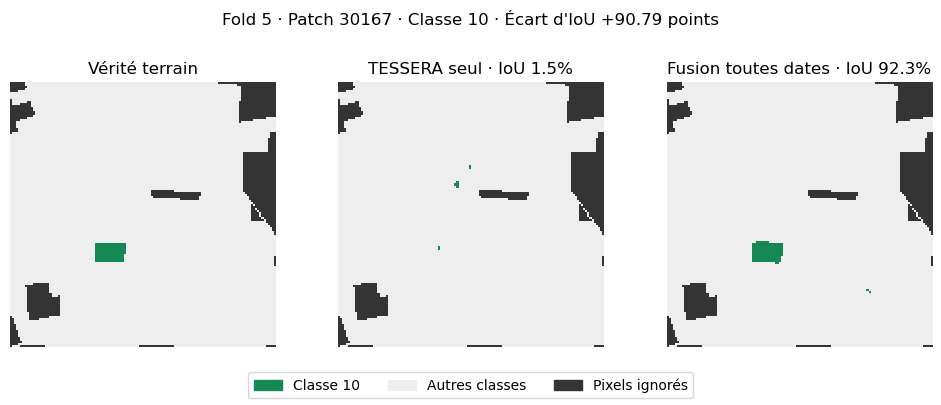

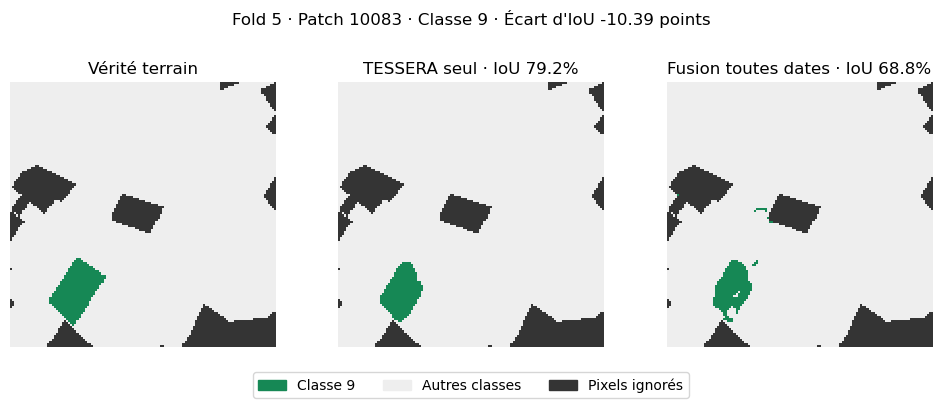

In [32]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Chercher un exemple de gain pour la classe 10 et de baisse pour la classe 9.
directions = {10: 1, 9: -1}
examples = {}
min_pixels = 128

fusion_model = models_test["Toutes les dates"].eval()
tessera_eval.eval()

with torch.inference_mode():
    for index in range(len(test_three)):
        sample = test_three[index]
        target = sample["target"].to(device_test, dtype=torch.long)
        valid = sample["valid"].to(
            device_test, dtype=torch.bool
        ).reshape_as(target)
        keep = valid & (target >= 0) & (target < n_classes)

        truth_by_class = {}
        for cls in directions:
            truth = (target == cls) & keep
            if truth.sum().item() >= min_pixels:
                truth_by_class[cls] = truth

        if not truth_by_class:
            continue

        embedding = sample["tessera"].to(device_test, dtype=torch.float32)[None]
        embedding = ((embedding - tessera_mean) / tessera_std).masked_fill(
            ~valid[None, None], 0
        )

        dummy_image = embedding.new_zeros((1, 10, *target.shape))
        pred_tessera = tessera_eval(dummy_image, embedding).argmax(dim=1)[0]

        # Reprendre le même prétraitement que pour le test toutes dates.
        row = test_three.rows.iloc[index]
        n_dates, original, _ = test_ten.selections[index]
        series = np.load(row["image_path"], mmap_mode="r")
        original_frames = dict(zip(
            original, sample["image"].reshape(3, 10, 128, 128)
        ))
        probability_sum = embedding.new_zeros((n_classes, *target.shape))

        for start in range(0, n_dates, 4):
            indices = range(start, min(start + 4, n_dates))
            frames = torch.stack([
                original_frames[j] if j in original_frames
                else torch.from_numpy(series[j].astype(np.float32))
                for j in indices
            ]).to(device_test, dtype=torch.float32)

            frame_valid = valid[None] & torch.isfinite(frames).all(dim=1)
            frames = ((frames - image_mean) / image_std).masked_fill(
                ~frame_valid[:, None], 0
            )
            logits = fusion_model(frames, embedding.expand(len(indices), -1, -1, -1))
            probability_sum += logits.float().softmax(dim=1).sum(dim=0)

        pred_fusion = probability_sum.argmax(dim=0)

        for cls, truth in truth_by_class.items():
            masks = [(pred == cls) & keep for pred in (pred_tessera, pred_fusion)]
            iou_tessera, iou_fusion = [
                (truth & mask).sum().item() / (truth | mask).sum().item()
                for mask in masks
            ]
            delta = iou_fusion - iou_tessera
            score = directions[cls] * delta
            if score > examples.get(cls, {}).get("score", 0):
                examples[cls] = {
                    "score": score,
                    "patch_id": sample["patch_id"],
                    "delta": delta,
                    "ious": (iou_tessera, iou_fusion),
                    "maps": [mask.cpu().numpy() for mask in (truth, *masks)],
                    "keep": keep.cpu().numpy(),
                }

cmap = ListedColormap(["#eeeeee", "#168855", "#343434"])

for cls in directions:
    if cls not in examples:
        print(f"Classe {cls} : aucun patch ne répond aux critères.")
        continue

    example = examples[cls]
    iou_tessera, iou_fusion = example["ious"]
    titles = (
        "Vérité terrain",
        f"TESSERA seul · IoU {iou_tessera:.1%}",
        f"Fusion toutes dates · IoU {iou_fusion:.1%}",
    )

    fig, axes = plt.subplots(1, 3, figsize=(10, 4))
    for ax, title, mask in zip(axes, titles, example["maps"]):
        ax.imshow(
            np.where(example["keep"], mask.astype(np.uint8), 2),
            cmap=cmap, vmin=0, vmax=2, interpolation="nearest",
        )
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(
        f"Fold 5 · Patch {example['patch_id']} · Classe {cls} · "
        f"Écart d'IoU {100 * example['delta']:+.2f} points"
    )
    fig.legend(
        handles=[
            Patch(color="#168855", label=f"Classe {cls}"),
            Patch(color="#eeeeee", label="Autres classes"),
            Patch(color="#343434", label="Pixels ignorés"),
        ],
        loc="lower center", ncol=3,
    )
    fig.tight_layout(rect=(0, 0.10, 1, 0.92))
    fig.savefig(out_test / f"fold5_classe_{cls}_patch_{example['patch_id']}.png",
                dpi=180, bbox_inches="tight")
    plt.show()

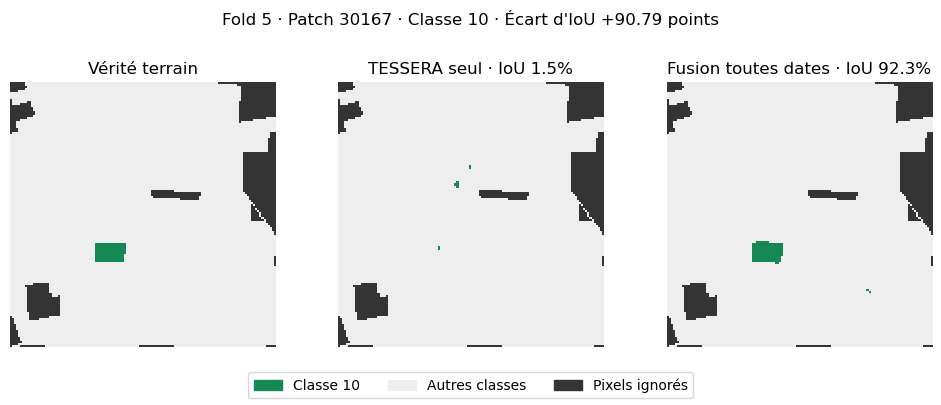

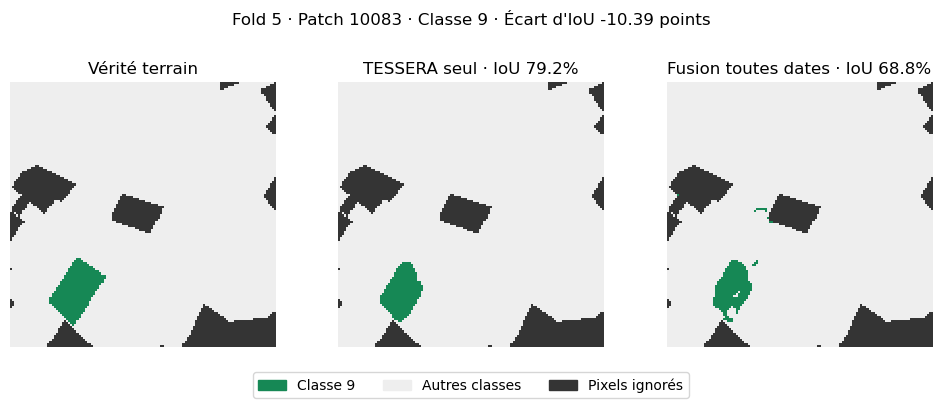

In [32]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Chercher un exemple de gain pour la classe 10 et de baisse pour la classe 9.
directions = {10: 1, 9: -1}
examples = {}
min_pixels = 128

fusion_model = models_test["Toutes les dates"].eval()
tessera_eval.eval()

with torch.inference_mode():
    for index in range(len(test_three)):
        sample = test_three[index]
        target = sample["target"].to(device_test, dtype=torch.long)
        valid = sample["valid"].to(
            device_test, dtype=torch.bool
        ).reshape_as(target)
        keep = valid & (target >= 0) & (target < n_classes)

        truth_by_class = {}
        for cls in directions:
            truth = (target == cls) & keep
            if truth.sum().item() >= min_pixels:
                truth_by_class[cls] = truth

        if not truth_by_class:
            continue

        embedding = sample["tessera"].to(device_test, dtype=torch.float32)[None]
        embedding = ((embedding - tessera_mean) / tessera_std).masked_fill(
            ~valid[None, None], 0
        )

        dummy_image = embedding.new_zeros((1, 10, *target.shape))
        pred_tessera = tessera_eval(dummy_image, embedding).argmax(dim=1)[0]

        # Reprendre le même prétraitement que pour le test toutes dates.
        row = test_three.rows.iloc[index]
        n_dates, original, _ = test_ten.selections[index]
        series = np.load(row["image_path"], mmap_mode="r")
        original_frames = dict(zip(
            original, sample["image"].reshape(3, 10, 128, 128)
        ))
        probability_sum = embedding.new_zeros((n_classes, *target.shape))

        for start in range(0, n_dates, 4):
            indices = range(start, min(start + 4, n_dates))
            frames = torch.stack([
                original_frames[j] if j in original_frames
                else torch.from_numpy(series[j].astype(np.float32))
                for j in indices
            ]).to(device_test, dtype=torch.float32)

            frame_valid = valid[None] & torch.isfinite(frames).all(dim=1)
            frames = ((frames - image_mean) / image_std).masked_fill(
                ~frame_valid[:, None], 0
            )
            logits = fusion_model(frames, embedding.expand(len(indices), -1, -1, -1))
            probability_sum += logits.float().softmax(dim=1).sum(dim=0)

        pred_fusion = probability_sum.argmax(dim=0)

        for cls, truth in truth_by_class.items():
            masks = [(pred == cls) & keep for pred in (pred_tessera, pred_fusion)]
            iou_tessera, iou_fusion = [
                (truth & mask).sum().item() / (truth | mask).sum().item()
                for mask in masks
            ]
            delta = iou_fusion - iou_tessera
            score = directions[cls] * delta
            if score > examples.get(cls, {}).get("score", 0):
                examples[cls] = {
                    "score": score,
                    "patch_id": sample["patch_id"],
                    "delta": delta,
                    "ious": (iou_tessera, iou_fusion),
                    "maps": [mask.cpu().numpy() for mask in (truth, *masks)],
                    "keep": keep.cpu().numpy(),
                }

cmap = ListedColormap(["#eeeeee", "#168855", "#343434"])

for cls in directions:
    if cls not in examples:
        print(f"Classe {cls} : aucun patch ne répond aux critères.")
        continue

    example = examples[cls]
    iou_tessera, iou_fusion = example["ious"]
    titles = (
        "Vérité terrain",
        f"TESSERA seul · IoU {iou_tessera:.1%}",
        f"Fusion toutes dates · IoU {iou_fusion:.1%}",
    )

    fig, axes = plt.subplots(1, 3, figsize=(10, 4))
    for ax, title, mask in zip(axes, titles, example["maps"]):
        ax.imshow(
            np.where(example["keep"], mask.astype(np.uint8), 2),
            cmap=cmap, vmin=0, vmax=2, interpolation="nearest",
        )
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(
        f"Fold 5 · Patch {example['patch_id']} · Classe {cls} · "
        f"Écart d'IoU {100 * example['delta']:+.2f} points"
    )
    fig.legend(
        handles=[
            Patch(color="#168855", label=f"Classe {cls}"),
            Patch(color="#eeeeee", label="Autres classes"),
            Patch(color="#343434", label="Pixels ignorés"),
        ],
        loc="lower center", ncol=3,
    )
    fig.tight_layout(rect=(0, 0.10, 1, 0.92))
    fig.savefig(out_test / f"fold5_classe_{cls}_patch_{example['patch_id']}.png",
                dpi=180, bbox_inches="tight")
    plt.show()

### Résultats sur le fold 5 selon le budget d’entraînement

Les checkpoints ont été sélectionnés sur le fold 4, puis évalués sur les 493 patchs du fold 5.

| Méthode | Budget d’entraînement | Époque retenue | mIoU sur le fold 5 |
|---|---:|---:|---:|
| Fusion à 20 dates | 20 époques | 19 | 61,95 % |
| Fusion toutes dates | 20 époques | 19 | 61,81 % |
| Fusion toutes dates | 61 époques | 59 | 62,73 % |

Avec un budget de 20 époques, les deux variantes obtiennent des résultats proches. La fusion à 20 dates devance la fusion toutes dates de **0,14 point de mIoU**. Avec un budget de 61 époques, la fusion toutes dates atteint **62,73 %** au checkpoint de l’époque 59, soit **2,28 points** de plus que TESSERA seul entraîné avec un budget de 20 époques (**60,45 %**).

In [33]:
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

path = Path(
    r"G:\Vmi\project\m2_image_results"
    r"\fusion_all_dates_full_20261115_102016_403369\best_20epochs.pt"
)

checkpoint_all20 = torch.load(path, map_location="cpu", weights_only=True)
model_all20 = deepcopy(models_test["Toutes les dates"])
model_all20.load_state_dict(checkpoint_all20["model_state_dict"], strict=True)
model_all20 = model_all20.to(device_test).eval()

assert len(test_three) == 493
print(f"Toutes les dates | Époque {checkpoint_all20['epoch']} | Fold 5")

cm_all20 = torch.zeros(
    (n_classes, n_classes), dtype=torch.int64, device=device_test
)

with torch.inference_mode():
    for index in range(len(test_three)):
        sample = test_three[index]
        row = test_three.rows.iloc[index]
        n_dates, original, _ = test_ten.selections[index]

        target = sample["target"].to(device_test, dtype=torch.long)
        valid = sample["valid"].to(
            device_test, dtype=torch.bool
        ).reshape_as(target)
        keep = valid & (target >= 0) & (target < n_classes)

        embedding = sample["tessera"].to(device_test, dtype=torch.float32)[None]
        embedding = ((embedding - tessera_mean) / tessera_std).masked_fill(
            ~valid[None, None], 0
        )

        # Reprendre les mêmes entrées que pour le test toutes dates précédent.
        series = np.load(row["image_path"], mmap_mode="r")
        assert series.shape == (n_dates, 10, *target.shape)
        reference_frames = dict(zip(
            original, sample["image"].reshape(3, 10, *target.shape)
        ))
        probability_sum = embedding.new_zeros((n_classes, *target.shape))

        for start in range(0, n_dates, 4):
            indices = range(start, min(start + 4, n_dates))
            frames = torch.stack([
                reference_frames[j] if j in reference_frames
                else torch.from_numpy(series[j].astype(np.float32))
                for j in indices
            ]).to(device_test, dtype=torch.float32)

            frame_valid = valid[None] & torch.isfinite(frames).all(dim=1)
            frames = ((frames - image_mean) / image_std).masked_fill(
                ~frame_valid[:, None], 0
            )
            logits = model_all20(
                frames, embedding.expand(len(indices), -1, -1, -1)
            )
            probability_sum += logits.float().softmax(dim=1).sum(dim=0)

        prediction = probability_sum.argmax(dim=0)
        codes = target[keep] * n_classes + prediction[keep]
        cm_all20 += torch.bincount(
            codes, minlength=n_classes ** 2
        ).reshape_as(cm_all20)

        done = index + 1
        if done % 50 == 0 or done == len(test_three):
            print(f"Test : {done}/{len(test_three)} patches", flush=True)

cm = cm_all20.cpu().numpy()
correct = cm.diagonal()
support = cm.sum(axis=1)
predicted = cm.sum(axis=0)
union = support + predicted - correct
present = union > 0

np.testing.assert_array_equal(
    support, classes_completes["pixels_reels"].to_numpy()
)

method = "Toutes les dates (budget de 20 époques)"
row_all20 = pd.DataFrame([{
    "Méthode": method,
    "mIoU test (%)": 100 * (correct[present] / union[present]).mean(),
    "Macro-F1 test (%)": 100 * (
        2 * correct[present] / (support + predicted)[present]
    ).mean(),
    "Exactitude pixel (%)": 100 * correct.sum() / cm.sum(),
}])

scores_final = pd.concat([scores_complets, row_all20], ignore_index=True)
baseline_miou = scores_final.loc[
    scores_final["Méthode"] == "TESSERA seul", "mIoU test (%)"
].iloc[0]
scores_final["Écart vs TESSERA (points)"] = (
    scores_final["mIoU test (%)"] - baseline_miou
)

iou_all20 = np.full(n_classes, np.nan)
iou_all20[present] = 100 * correct[present] / union[present]
classes_final = classes_completes.assign(**{method: iou_all20})

scores_final.to_csv(out_test / "scores_test_avec_budget_20.csv", index=False)
classes_final.to_csv(out_test / "iou_par_classe_avec_budget_20.csv", index=False)

display(scores_final.round(2))

miou_20dates = scores_complets.loc[
    scores_complets["Méthode"] == "20 dates", "mIoU test (%)"
].iloc[0]
delta = row_all20.loc[0, "mIoU test (%)"] - miou_20dates
print(f"Écart toutes dates − 20 dates à budget égal : {delta:+.2f} points")

Toutes les dates | Époque 19 | Fold 5
Test : 50/493 patches
Test : 100/493 patches
Test : 150/493 patches
Test : 200/493 patches
Test : 250/493 patches
Test : 300/493 patches
Test : 350/493 patches
Test : 400/493 patches
Test : 450/493 patches
Test : 493/493 patches


,Méthode,mIoU test (%),Macro-F1 test (%),Exactitude pixel (%),Écart vs TESSERA (points)
0,Sentinel-2 seul,38.59,50.98,74.20,-21.86
1,TESSERA seul,60.45,73.44,83.04,0.00
2,1 date,61.11,74.15,83.26,0.66
3,3 dates,61.13,74.09,83.06,0.69
4,10 dates,61.09,74.10,83.22,0.64
5,20 dates,61.95,74.85,83.21,1.50
6,Toutes les dates,62.73,75.52,83.51,2.28
7,Toutes les dates (budget de 20 époques),61.81,74.71,83.31,1.37


Écart toutes dates − 20 dates à budget égal : -0.14 points


### Reprise de l’entraînement — Fusion à 20 dates

L’entraînement reprend à partir du checkpoint de la 20e époque et se poursuit jusqu’à la 61e époque. Sur les 475 patchs de validation du fold 4, les probabilités prédites à partir des 20 scènes de chaque patch sont moyennées.

| Étape | Meilleure époque | mIoU de validation |
|---|---:|---:|
| Avant la reprise | 19 | 63,17 % |
| Après la reprise | 56 | **64,98 %** |

La reprise améliore le meilleur mIoU de validation de **1,81 point de pourcentage**. Le checkpoint de la 56e époque est retenu pour le test sur le fold 5.

In [34]:
from datetime import datetime, timedelta
from pathlib import Path
from shutil import copy2
from time import perf_counter

import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from torch.utils.data import DataLoader


def reprendre_20_dates(epochs=61):
    root = Path(r"G:\Vmi\project\m2_image_results")
    source = root / "fusion_20dates_full_20261115_085835_429718"

    for filename in ("last.pt", "best.pt", "history.csv"):
        if not (source / filename).is_file():
            raise FileNotFoundError(source / filename)

    # Reprendre les poids et l'état de l'optimiseur à la fin de l'époque 20.
    checkpoint = torch.load(
        source / "last.pt", map_location="cpu", weights_only=True
    )
    completed = int(checkpoint["epoch"])
    history_df = pd.read_csv(source / "history.csv")

    if completed != 20 or history_df["epoch"].tolist() != list(range(1, 21)):
        raise ValueError("La reprise attend le checkpoint et l'historique des époques 1 à 20.")
    if epochs <= completed:
        raise ValueError("Le nombre total d'époques doit être supérieur à 20.")

    torch.manual_seed(42)
    train_data = PastisTwentyDateDataset(train10, training=True, seed=42)
    val_data = PastisTwentyDateDataset(val10, training=False, seed=42)
    assert (len(train_data), len(val_data)) == (1431, 475)

    train_loader = DataLoader(
        train_data, batch_size=2, shuffle=True, num_workers=0
    )
    val_loader = DataLoader(
        val_data, batch_size=1, shuffle=False, num_workers=0
    )

    model = FusionModel().to(device10)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    folder = root / f"fusion_20dates_{epochs}epochs_{stamp}"
    folder.mkdir()

    # Conserver le meilleur modèle des 20 premières époques.
    copy2(source / "best.pt", folder / "best_20epochs.pt")
    copy2(source / "best.pt", folder / "best.pt")
    copy2(source / "last.pt", folder / "last.pt")
    copy2(source / "history.csv", folder / "history.csv")

    history = history_df.to_dict("records")
    best_miou = float(history_df["val_miou"].max())
    num_classes = 19
    ignore_index = 19
    counts = [len(selected) for _, _, selected, _ in val_data.selections]

    print(f"Appareil : {device10}")
    print(f"Reprise : époques {completed + 1} à {epochs}")
    print(f"Validation : {min(counts)}–{max(counts)} scènes par patch")
    print(f"Meilleur mIoU avant reprise : {best_miou:.2%}")
    print(f"Résultats : {folder}", flush=True)

    run_start = perf_counter()

    for epoch in range(completed + 1, epochs + 1):
        epoch_start = perf_counter()
        train_data.epoch = epoch - 1
        model.train()
        loss_sum = 0.0
        pixel_count = 0

        print(f"\nÉpoque {epoch}/{epochs}", flush=True)

        for step, batch in enumerate(train_loader, start=1):
            frames, tessera, target, valid = prepare_batch10(batch)
            count = int((target != ignore_index).sum().item())

            if count:
                image = normalize_image10(frames[:, 0], valid)
                optimizer.zero_grad(set_to_none=True)
                logits = model(image, tessera)
                loss = F.cross_entropy(logits, target, ignore_index=ignore_index)
                loss.backward()
                optimizer.step()

                loss_sum += loss.item() * count
                pixel_count += count

            if step % 100 == 0 or step == len(train_loader):
                print(f"  Entraînement : {step}/{len(train_loader)} lots", flush=True)

        if pixel_count == 0:
            raise ValueError("Aucun pixel annoté valide pour l'entraînement.")

        train_seconds = perf_counter() - epoch_start
        val_start = perf_counter()
        model.eval()
        confusion = torch.zeros(
            (num_classes, num_classes), dtype=torch.int64, device=device10
        )

        with torch.inference_mode():
            for step, batch in enumerate(val_loader, start=1):
                frames, tessera, target, valid = prepare_batch10(batch)
                probability_sum = torch.zeros(
                    (num_classes, *target.shape[-2:]),
                    dtype=torch.float32,
                    device=device10,
                )

                # Prédire les 20 scènes par groupes de quatre.
                for chunk in frames[0].split(4, dim=0):
                    images = normalize_image10(chunk, valid)
                    embeddings = tessera.expand(len(chunk), -1, -1, -1)
                    probabilities = model(images, embeddings).float().softmax(dim=1)
                    probability_sum += probabilities.sum(dim=0)

                prediction = probability_sum.argmax(dim=0)
                keep = target[0] != ignore_index
                codes = target[0][keep] * num_classes + prediction[keep]
                confusion += torch.bincount(
                    codes, minlength=num_classes ** 2
                ).reshape_as(confusion)

                if step % 50 == 0 or step == len(val_loader):
                    print(f"  Validation : {step}/{len(val_loader)} patches", flush=True)

        confusion = confusion.cpu()
        val_seconds = perf_counter() - val_start

        correct = confusion.diag()
        union = confusion.sum(0) + confusion.sum(1) - correct
        present = union > 0
        if not present.any().item():
            raise ValueError("Aucun pixel annoté valide pour la validation.")

        miou = (correct[present] / union[present]).mean().item()
        accuracy = (correct.sum() / confusion.sum()).item()
        train_loss = loss_sum / pixel_count

        checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": miou,
            "val_accuracy": accuracy,
        }
        torch.save(checkpoint, folder / "last.pt")

        if miou > best_miou:
            best_miou = miou
            torch.save(checkpoint, folder / "best.pt")

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_miou": miou,
            "val_accuracy": accuracy,
            "train_seconds": round(train_seconds, 1),
            "val_seconds": round(val_seconds, 1),
            "epoch_seconds": round(perf_counter() - epoch_start, 1),
        })
        pd.DataFrame(history).to_csv(folder / "history.csv", index=False)

        elapsed = perf_counter() - run_start
        remaining = elapsed / (epoch - completed) * (epochs - epoch)
        print(
            f"Train loss : {train_loss:.4f} | "
            f"Val mIoU : {miou:.2%} | Val accuracy : {accuracy:.2%}",
            flush=True,
        )
        print(
            f"  Train : {timedelta(seconds=round(train_seconds))} | "
            f"Val : {timedelta(seconds=round(val_seconds))} | "
            f"Écoulé depuis la reprise : {timedelta(seconds=round(elapsed))} | "
            f"Reste estimé : {timedelta(seconds=round(remaining))}",
            flush=True,
        )

    history_df = pd.DataFrame(history)
    best = history_df.loc[history_df["val_miou"].idxmax()]
    print(f"\nMeilleure époque sur 1–{epochs} : {int(best['epoch'])}")
    print(f"Meilleur mIoU de validation : {best['val_miou']:.2%}")
    print(f"Durée de la reprise : {timedelta(seconds=round(perf_counter() - run_start))}")
    print(f"Checkpoint : {folder / 'best.pt'}")
    return folder, history_df


out20_61, history20_61 = reprendre_20_dates(epochs=61)
display(history20_61.nlargest(5, "val_miou"))

Appareil : cuda
Reprise : époques 21 à 61
Validation : 20–20 scènes par patch
Meilleur mIoU avant reprise : 63.17%
Résultats : G:\Vmi\project\m2_image_results\fusion_20dates_61epochs_20261115_192550_818277

Époque 21/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/475 patches
  Validation : 100/475 patches
  Validation : 150/475 patches
  Validation : 200/475 patches
  Validation : 250/475 patches
  Validation : 300/475 patches
  Validation : 350/475 patches
  Validation : 400/475 patches
  Validation : 450/475 patches
  Validation : 475/475 patches
Train loss : 0.4303 | Val mIoU : 61.50% | Val accuracy : 83.51%
  Train : 0:03:08 | Val : 0:01:29 | Écoulé depuis la reprise : 0:04:36 | Reste estimé : 3:04:06

Époque 22/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lo

,epoch,train_loss,val_miou,val_accuracy,train_seconds,val_seconds,epoch_seconds
55,56,0.358010,0.649818,0.842733,173.6,88.1,261.7
38,39,0.392587,0.648448,0.841709,169.7,88.0,257.8
42,43,0.385308,0.646835,0.842712,169.4,90.1,259.5
53,54,0.363918,0.646602,0.843345,179.0,88.0,267.0
37,38,0.397764,0.645887,0.843234,160.7,82.2,242.9


### Fusion à 20 dates — Test sur le fold 5

Le modèle a été entraîné pendant 61 époques. Le checkpoint de l’époque 56, sélectionné sur le fold 4, a été évalué sur les 493 patchs du fold 5.

| mIoU | Macro-F1 | Exactitude par pixel |
|---:|---:|---:|
| 63,76 % | 76,46 % | 83,61 % |

À budget d’entraînement égal, la fusion à 20 dates obtient un mIoU supérieur de **1,03 point** à celui de la fusion toutes dates (62,73 %).

In [35]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import torch
from IPython.display import display

folder = Path(
    r"G:\Vmi\project\m2_image_results"
    r"\fusion_20dates_61epochs_20261115_192550_818277"
)
checkpoint = torch.load(folder / "best.pt", map_location="cpu", weights_only=True)
assert int(checkpoint["epoch"]) == 56
assert len(test_twenty) == 493

model_20_61 = FusionModel().to(device_test)
model_20_61.load_state_dict(checkpoint["model_state_dict"], strict=True)
model_20_61.eval()

image_mean, image_std = (x.to(device_test) for x in stats_by_input["image"])
tessera_mean, tessera_std = (x.to(device_test) for x in stats_by_input["tessera"])
n_classes = 19
confusion = torch.zeros(
    (n_classes, n_classes), dtype=torch.int64, device=device_test
)

start = perf_counter()
print("Fusion 20 dates | Checkpoint : époque 56 | Test : Fold 5", flush=True)

with torch.inference_mode():
    for index in range(len(test_twenty)):
        sample = test_twenty[index]
        target = sample["target"].to(device_test, dtype=torch.long)
        valid = sample["valid"].to(device_test, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < n_classes)

        embedding = sample["tessera"].to(device_test, dtype=torch.float32)[None]
        embedding = ((embedding - tessera_mean) / tessera_std).masked_fill(
            ~valid[None, None], 0
        )
        frames = sample["frames"]
        assert frames.shape[0] == 20

        probability_sum = embedding.new_zeros((n_classes, *target.shape))
        for chunk in frames.split(4, dim=0):
            chunk = chunk.to(device_test, dtype=torch.float32)
            frame_valid = valid[None] & torch.isfinite(chunk).all(dim=1)
            images = ((chunk - image_mean) / image_std).masked_fill(
                ~frame_valid[:, None], 0
            )
            logits = model_20_61(images, embedding.expand(len(chunk), -1, -1, -1))
            probability_sum += logits.float().softmax(dim=1).sum(dim=0)

        # La somme et la moyenne donnent la même classe par argmax.
        prediction = probability_sum.argmax(dim=0)
        codes = target[keep] * n_classes + prediction[keep]
        confusion += torch.bincount(
            codes, minlength=n_classes ** 2
        ).reshape_as(confusion)

        done = index + 1
        if done % 50 == 0 or done == len(test_twenty):
            print(f"Test : {done}/{len(test_twenty)} patches", flush=True)

cm = confusion.cpu().numpy()
correct = cm.diagonal()
support = cm.sum(axis=1)
predicted = cm.sum(axis=0)
union = support + predicted - correct
present = union > 0
iou = np.full(n_classes, np.nan)
iou[present] = correct[present] / union[present]

miou = 100 * iou[present].mean()
scores_20_61 = pd.DataFrame([{
    "Méthode": "20 dates (budget de 61 époques)",
    "Époque retenue": int(checkpoint["epoch"]),
    "mIoU test (%)": miou,
    "Macro-F1 test (%)": 100 * (
        2 * correct[present] / (support + predicted)[present]
    ).mean(),
    "Exactitude pixel (%)": 100 * correct.sum() / cm.sum(),
}])

classes_20_61 = pd.DataFrame({
    "classe": np.arange(n_classes),
    "pixels_reels": support,
    "IoU test (%)": 100 * iou,
})

scores_20_61.to_csv(folder / "scores_fold5.csv", index=False)
classes_20_61.to_csv(folder / "iou_par_classe_fold5.csv", index=False)
display(scores_20_61.round(2))
print(f"Écart vs toutes les dates (62,73 %) : {miou - 62.73:+.2f} points")
print(f"Durée du test : {perf_counter() - start:.1f} s")

Fusion 20 dates | Checkpoint : époque 56 | Test : Fold 5
Test : 50/493 patches
Test : 100/493 patches
Test : 150/493 patches
Test : 200/493 patches
Test : 250/493 patches
Test : 300/493 patches
Test : 350/493 patches
Test : 400/493 patches
Test : 450/493 patches
Test : 493/493 patches


,Méthode,Époque retenue,mIoU test (%),Macro-F1 test (%),Exactitude pixel (%)
0,20 dates (budget de 61 époques),56,63.76,76.46,83.61


Écart vs toutes les dates (62,73 %) : +1.03 points
Durée du test : 82.5 s


## 10 61 epoche

In [ ]:
from datetime import datetime, timedelta
from pathlib import Path
from shutil import copy2
from time import perf_counter

import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from torch.utils.data import DataLoader


def reprendre_10_dates(epochs=61):
    root = Path(r"G:\Vmi\project\m2_image_results")
    source = root / "fusion_10dates_full_20261115_012540_510859"

    checkpoint = torch.load(
        source / "last.pt", map_location="cpu", weights_only=True
    )
    history = pd.read_csv(source / "history.csv")
    completed = int(checkpoint["epoch"])

    if completed != 20 or history["epoch"].tolist() != list(range(1, 21)):
        raise ValueError("La reprise attend le checkpoint et l'historique à l'époque 20.")
    if epochs <= completed:
        raise ValueError("Le nombre total d'époques doit dépasser 20.")

    torch.manual_seed(42)
    train_data = PastisTenDateDataset(train_three, training=True, seed=42)
    val_data = PastisTenDateDataset(val_three, training=False, seed=42)
    assert (len(train_data), len(val_data)) == (1431, 475)

    train_loader = DataLoader(
        train_data, batch_size=2, shuffle=True, num_workers=0
    )
    val_loader = DataLoader(
        val_data, batch_size=2, shuffle=False, num_workers=0
    )

    model = FusionModel().to(device10)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    folder = root / f"fusion_10dates_{epochs}epochs_{stamp}"
    folder.mkdir()

    # Conserver les résultats et le meilleur modèle des 20 premières époques.
    for filename in ("best.pt", "last.pt", "history.csv"):
        copy2(source / filename, folder / filename)
    copy2(source / "best.pt", folder / "best_20epochs.pt")

    records = history.to_dict("records")
    best_miou = float(history["val_miou"].max())
    num_classes = 19
    ignore_index = 19
    run_start = perf_counter()

    print(f"Appareil : {device10} | Reprise : époques {completed + 1} à {epochs}")
    print(f"Meilleur mIoU avant reprise : {best_miou:.2%}")
    print(f"Résultats : {folder}", flush=True)

    for epoch in range(completed + 1, epochs + 1):
        epoch_start = perf_counter()
        model.train()
        loss_sum = 0.0
        pixel_count = 0
        print(f"\nÉpoque {epoch}/{epochs}", flush=True)

        for step, batch in enumerate(train_loader, start=1):
            frames, tessera, target, valid = prepare_batch10(batch)
            count = int((target != ignore_index).sum().item())

            if count:
                # Le dataset tire déjà une scène parmi les dix pour chaque patch.
                image = normalize_image10(frames[:, 0], valid)
                optimizer.zero_grad(set_to_none=True)
                loss = F.cross_entropy(
                    model(image, tessera), target, ignore_index=ignore_index
                )
                loss.backward()
                optimizer.step()

                loss_sum += loss.item() * count
                pixel_count += count

            if step % 100 == 0 or step == len(train_loader):
                print(f"  Entraînement : {step}/{len(train_loader)} lots", flush=True)

        if not pixel_count:
            raise ValueError("Aucun pixel annoté valide pour l'entraînement.")

        train_seconds = perf_counter() - epoch_start
        val_start = perf_counter()
        model.eval()
        cm = torch.zeros(
            (num_classes, num_classes), dtype=torch.int64, device=device10
        )

        with torch.inference_mode():
            for step, batch in enumerate(val_loader, start=1):
                frames, tessera, target, valid = prepare_batch10(batch)
                probability_sum = torch.zeros(
                    (target.shape[0], num_classes, *target.shape[-2:]),
                    dtype=torch.float32,
                    device=device10,
                )

                # La somme et la moyenne donnent le même argmax.
                for frame in frames.unbind(dim=1):
                    image = normalize_image10(frame, valid)
                    probability_sum += model(image, tessera).float().softmax(dim=1)

                prediction = probability_sum.argmax(dim=1)
                keep = target != ignore_index
                codes = target[keep] * num_classes + prediction[keep]
                cm += torch.bincount(
                    codes, minlength=num_classes ** 2
                ).reshape_as(cm)

                if step % 50 == 0 or step == len(val_loader):
                    print(f"  Validation : {step}/{len(val_loader)} lots", flush=True)

        cm = cm.cpu()
        val_seconds = perf_counter() - val_start
        correct = cm.diag()
        union = cm.sum(0) + cm.sum(1) - correct
        present = union > 0

        if not present.any().item():
            raise ValueError("Aucun pixel annoté valide pour la validation.")

        miou = (correct[present] / union[present]).mean().item()
        accuracy = (correct.sum() / cm.sum()).item()
        train_loss = loss_sum / pixel_count

        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": miou,
            "val_accuracy": accuracy,
        }
        torch.save(state, folder / "last.pt")

        if miou > best_miou:
            best_miou = miou
            torch.save(state, folder / "best.pt")

        records.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_miou": miou,
            "val_accuracy": accuracy,
            "train_seconds": round(train_seconds, 1),
            "val_seconds": round(val_seconds, 1),
            "epoch_seconds": round(perf_counter() - epoch_start, 1),
        })
        pd.DataFrame(records).to_csv(folder / "history.csv", index=False)

        elapsed = perf_counter() - run_start
        remaining = elapsed / (epoch - completed) * (epochs - epoch)
        print(
            f"Train loss : {train_loss:.4f} | "
            f"Val mIoU : {miou:.2%} | Val accuracy : {accuracy:.2%}",
            flush=True,
        )
        print(
            f"  Train : {timedelta(seconds=round(train_seconds))} | "
            f"Val : {timedelta(seconds=round(val_seconds))} | "
            f"Écoulé depuis la reprise : {timedelta(seconds=round(elapsed))} | "
            f"Reste estimé : {timedelta(seconds=round(remaining))}",
            flush=True,
        )

    history = pd.DataFrame(records)
    best = history.loc[history["val_miou"].idxmax()]
    print(f"\nMeilleure époque sur 1–{epochs} : {int(best['epoch'])}")
    print(f"Meilleur mIoU de validation : {best['val_miou']:.2%}")
    print(f"Checkpoint : {folder / 'best.pt'}")
    return folder, history


out10_61, history10_61 = reprendre_10_dates(epochs=61)
display(history10_61.nlargest(5, "val_miou"))

Appareil : cuda | Reprise : époques 21 à 61
Meilleur mIoU avant reprise : 62.68%
Résultats : G:\Vmi\project\m2_image_results\fusion_10dates_61epochs_20261115_230045_421275

Époque 21/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/238 lots
  Validation : 100/238 lots
  Validation : 150/238 lots
  Validation : 200/238 lots
  Validation : 238/238 lots
Train loss : 0.4297 | Val mIoU : 60.46% | Val accuracy : 83.13%
  Train : 0:02:52 | Val : 0:01:10 | Écoulé depuis la reprise : 0:04:02 | Reste estimé : 2:41:01

Époque 22/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/238

#### restart

In [17]:
class PastisTenDateDataset(Dataset):
    def __init__(self, base_three, training, seed=42):
        self.base = base_three
        self.training = training
        self.rng = np.random.default_rng(seed)
        self.selections = []

        for index, row in base_three.rows.iterrows():
            pid = int(row["patch_id"])
            dates, (spring_idx, late_idx) = base_three.side_dates[index]
            july_target = pd.Timestamp(
                "2019-07-02" if pid == 30708 else "2019-07-06"
            )
            july_idx = int(np.argmin(np.abs((dates - july_target).days)))

            # Garder les trois dates de référence et combler les grands intervalles.
            original = (spring_idx, july_idx, late_idx)
            if len(set(original)) != 3 or len(dates) < 10:
                raise ValueError(f"Dix dates distinctes requises pour le patch {pid}.")

            offsets = np.asarray((dates - dates.min()).days)
            selected = list(original)
            remaining = set(range(len(dates))) - set(original)
            while len(selected) < 10:
                candidate = max(
                    sorted(remaining),
                    key=lambda j: min(abs(offsets[j] - offsets[k]) for k in selected),
                )
                selected.append(candidate)
                remaining.remove(candidate)

            self.selections.append((len(dates), original, selected))

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        sample = self.base[index]
        row = self.base.rows.iloc[index]
        n_dates, original, selected = self.selections[index]
        series = np.load(row["image_path"], mmap_mode="r")
        if series.shape != (n_dates, 10, 128, 128):
            raise ValueError(f"Série Sentinel-2 incohérente : {sample['patch_id']}")

        # Réutiliser exactement les trois images de l'expérience précédente.
        original_frames = dict(zip(original, sample["image"].reshape(3, 10, 128, 128)))
        indices = [selected[self.rng.integers(10)]] if self.training else selected
        frames = torch.stack([
            original_frames[j] if j in original_frames
            else torch.from_numpy(series[j].astype(np.float32))
            for j in indices
        ])

        return {
            "frames": frames,
            "tessera": sample["tessera"],
            "target": sample["target"],
            "valid": sample["valid"],
        }

In [23]:
import torch.nn as nn


def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.GroupNorm(4, out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.GroupNorm(4, out_channels),
        nn.ReLU(inplace=True),
    )

N_CLASSES = 19

In [24]:
from datetime import timedelta
from pathlib import Path
from time import perf_counter

import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from torch.utils.data import DataLoader

import numpy as np
from torch.utils.data import Dataset

class PastisTenDateDataset(Dataset):
    def __init__(self, base_three, training, seed=42):
        self.base = base_three
        self.training = training
        self.rng = np.random.default_rng(seed)
        self.selections = []

        for index, row in base_three.rows.iterrows():
            pid = int(row["patch_id"])
            dates, (spring_idx, late_idx) = base_three.side_dates[index]
            july_target = pd.Timestamp(
                "2019-07-02" if pid == 30708 else "2019-07-06"
            )
            july_idx = int(np.argmin(np.abs((dates - july_target).days)))

            # Garder les trois dates de référence et combler les grands intervalles.
            original = (spring_idx, july_idx, late_idx)
            if len(set(original)) != 3 or len(dates) < 10:
                raise ValueError(f"Dix dates distinctes requises pour le patch {pid}.")

            offsets = np.asarray((dates - dates.min()).days)
            selected = list(original)
            remaining = set(range(len(dates))) - set(original)
            while len(selected) < 10:
                candidate = max(
                    sorted(remaining),
                    key=lambda j: min(abs(offsets[j] - offsets[k]) for k in selected),
                )
                selected.append(candidate)
                remaining.remove(candidate)

            self.selections.append((len(dates), original, selected))

    def __len__(self):
        return len(self.base)

    def __getitem__(self, index):
        sample = self.base[index]
        row = self.base.rows.iloc[index]
        n_dates, original, selected = self.selections[index]
        series = np.load(row["image_path"], mmap_mode="r")
        if series.shape != (n_dates, 10, 128, 128):
            raise ValueError(f"Série Sentinel-2 incohérente : {sample['patch_id']}")

        # Réutiliser exactement les trois images de l'expérience précédente.
        original_frames = dict(zip(original, sample["image"].reshape(3, 10, 128, 128)))
        indices = [selected[self.rng.integers(10)]] if self.training else selected
        frames = torch.stack([
            original_frames[j] if j in original_frames
            else torch.from_numpy(series[j].astype(np.float32))
            for j in indices
        ])

        return {
            "frames": frames,
            "tessera": sample["tessera"],
            "target": sample["target"],
            "valid": sample["valid"],
        }



def terminer_10_dates():
    folder = Path(
        r"G:\Vmi\project\m2_image_results"
        r"\fusion_10dates_61epochs_20261115_230045_421275"
    )
    checkpoint = torch.load(
        folder / "last.pt", map_location="cpu", weights_only=True
    )
    history = pd.read_csv(folder / "history.csv")
    completed = int(checkpoint["epoch"])

    if history["epoch"].tolist() != list(range(1, completed + 1)):
        raise ValueError("Le checkpoint et l'historique ne sont pas synchronisés.")
    if completed == 61:
        print("Les 61 époques sont déjà terminées.")
        display(history.nlargest(5, "val_miou"))
        return history
    if not 58 <= completed < 61:
        raise ValueError(f"Époque inattendue dans last.pt : {completed}.")

    torch.manual_seed(42 + completed)
    train_data = PastisTenDateDataset(
        train_three, training=True, seed=42 + completed
    )
    val_data = PastisTenDateDataset(val_three, training=False, seed=42)
    assert (len(train_data), len(val_data)) == (1431, 475)

    train_loader = DataLoader(
        train_data, batch_size=2, shuffle=True, num_workers=0
    )
    val_loader = DataLoader(
        val_data, batch_size=2, shuffle=False, num_workers=0
    )

    model = FusionModel().to(device10)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    best_miou = float(history["val_miou"].max())
    records = history.to_dict("records")
    start = perf_counter()

    print(f"Reprise : époques {completed + 1} à 61 | Appareil : {device10}", flush=True)

    for epoch in range(completed + 1, 62):
        epoch_start = perf_counter()
        model.train()
        loss_sum = 0.0
        pixel_count = 0
        print(f"\nÉpoque {epoch}/61", flush=True)

        for step, batch in enumerate(train_loader, start=1):
            frames, tessera, target, valid = prepare_batch10(batch)
            count = int((target != 19).sum().item())

            if count:
                # Le dataset tire une scène parmi les dix pour chaque patch.
                image = normalize_image10(frames[:, 0], valid)
                optimizer.zero_grad(set_to_none=True)
                loss = F.cross_entropy(model(image, tessera), target, ignore_index=19)
                loss.backward()
                optimizer.step()
                loss_sum += loss.item() * count
                pixel_count += count

            if step % 100 == 0 or step == len(train_loader):
                print(f"  Entraînement : {step}/{len(train_loader)} lots", flush=True)

        if not pixel_count:
            raise ValueError("Aucun pixel valide pour l'entraînement.")

        train_seconds = perf_counter() - epoch_start
        val_start = perf_counter()
        model.eval()
        cm = torch.zeros((19, 19), dtype=torch.int64, device=device10)

        with torch.inference_mode():
            for step, batch in enumerate(val_loader, start=1):
                frames, tessera, target, valid = prepare_batch10(batch)
                probability_sum = torch.zeros(
                    (target.shape[0], 19, *target.shape[-2:]),
                    dtype=torch.float32,
                    device=device10,
                )
                for frame in frames.unbind(dim=1):
                    image = normalize_image10(frame, valid)
                    probability_sum += model(image, tessera).float().softmax(dim=1)

                prediction = probability_sum.argmax(dim=1)
                keep = target != 19
                codes = target[keep] * 19 + prediction[keep]
                cm += torch.bincount(codes, minlength=19**2).reshape_as(cm)

                if step % 50 == 0 or step == len(val_loader):
                    print(f"  Validation : {step}/{len(val_loader)} lots", flush=True)

        cm = cm.cpu()
        val_seconds = perf_counter() - val_start
        correct = cm.diag()
        union = cm.sum(0) + cm.sum(1) - correct
        present = union > 0
        if not present.any().item():
            raise ValueError("Aucun pixel valide pour la validation.")

        miou = (correct[present] / union[present]).mean().item()
        accuracy = (correct.sum() / cm.sum()).item()
        train_loss = loss_sum / pixel_count

        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": miou,
            "val_accuracy": accuracy,
        }
        if miou > best_miou:
            best_miou = miou
            torch.save(state, folder / "best.tmp")
            (folder / "best.tmp").replace(folder / "best.pt")

        torch.save(state, folder / "last.tmp")
        (folder / "last.tmp").replace(folder / "last.pt")

        records.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_miou": miou,
            "val_accuracy": accuracy,
            "train_seconds": round(train_seconds, 1),
            "val_seconds": round(val_seconds, 1),
            "epoch_seconds": round(perf_counter() - epoch_start, 1),
        })
        pd.DataFrame(records).to_csv(folder / "history.tmp", index=False)
        (folder / "history.tmp").replace(folder / "history.csv")

        elapsed = perf_counter() - start
        remaining = elapsed / (epoch - completed) * (61 - epoch)
        print(
            f"Val mIoU : {miou:.2%} | Meilleur : {best_miou:.2%} | "
            f"Reste estimé : {timedelta(seconds=round(remaining))}",
            flush=True,
        )

    history = pd.DataFrame(records)
    best = history.loc[history["val_miou"].idxmax()]
    print(f"\nMeilleure époque : {int(best['epoch'])} | mIoU : {best['val_miou']:.2%}")
    print(f"Checkpoint : {folder / 'best.pt'}")
    display(history.nlargest(5, "val_miou"))
    return history

In [33]:
import torch

device10 = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reprendre le dataset mono-date utilisé pour la normalisation initiale.
dataset_norm = train_three.base
assert len(dataset_norm) == 1431

sums = {"image": torch.zeros(10, dtype=torch.float64),
        "tessera": torch.zeros(128, dtype=torch.float64)}
squares = {name: torch.zeros_like(total) for name, total in sums.items()}
pixel_count = 0

for index in range(len(dataset_norm)):
    sample = dataset_norm[index]
    valid = sample["valid"].bool().reshape(sample["target"].shape)
    pixel_count += int(valid.sum())

    for name in sums:
        values = sample[name][:, valid].to(torch.float64)
        sums[name] += values.sum(dim=1)
        squares[name] += values.square().sum(dim=1)

    if (index + 1) % 100 == 0 or index + 1 == len(dataset_norm):
        print(f"Normalisation : {index + 1}/{len(dataset_norm)} patches", flush=True)

if pixel_count == 0:
    raise ValueError("Aucun pixel valide pour calculer la normalisation.")

stats_by_input = {}
for name in sums:
    mean = sums[name] / pixel_count
    variance = (squares[name] / pixel_count - mean.square()).clamp_min(0)
    std = variance.sqrt().clamp_min(1e-6)
    stats_by_input[name] = tuple(
        value.to(device=device10, dtype=torch.float32).reshape(1, -1, 1, 1)
        for value in (mean, std)
    )

stats10 = stats_by_input


def prepare_batch10(batch):
    target = batch["target"].to(device10, dtype=torch.long)
    valid = batch["valid"].to(device10, dtype=torch.bool).reshape_as(target)
    keep = valid & (target >= 0) & (target < 19)
    target = target.masked_fill(~keep, 19)

    frames = batch["frames"].to(device10, dtype=torch.float32)
    tessera = batch["tessera"].to(device10, dtype=torch.float32)
    mean, std = stats10["tessera"]
    tessera = ((tessera - mean) / std).masked_fill(~valid[:, None], 0)
    return frames, tessera, target, valid


def normalize_image10(frame, valid):
    frame_valid = valid & torch.isfinite(frame).all(dim=1)
    mean, std = stats10["image"]
    return ((frame - mean) / std).masked_fill(~frame_valid[:, None], 0)


print(f"Appareil : {device10} | Pixels utilisés : {pixel_count:,}")
print({name: mean.shape[1] for name, (mean, _) in stats10.items()})

Normalisation : 100/1431 patches
Normalisation : 200/1431 patches
Normalisation : 300/1431 patches
Normalisation : 400/1431 patches
Normalisation : 500/1431 patches
Normalisation : 600/1431 patches
Normalisation : 700/1431 patches
Normalisation : 800/1431 patches
Normalisation : 900/1431 patches
Normalisation : 1000/1431 patches
Normalisation : 1100/1431 patches
Normalisation : 1200/1431 patches
Normalisation : 1300/1431 patches
Normalisation : 1400/1431 patches
Normalisation : 1431/1431 patches
Appareil : cuda | Pixels utilisés : 23,445,504
{'image': 10, 'tessera': 128}


In [34]:
history10_61 = terminer_10_dates()

Reprise : époques 59 à 61 | Appareil : cuda

Époque 59/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/238 lots
  Validation : 100/238 lots
  Validation : 150/238 lots
  Validation : 200/238 lots
  Validation : 238/238 lots
Val mIoU : 63.95% | Meilleur : 64.88% | Reste estimé : 0:06:34

Époque 60/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/238 lots
  Validation : 100/238 lots
  Validation : 150/238 lots
  Validation : 200/238 lots
  Validation : 238/238 lots
Val mIoU : 63.55% | Meilleur : 64.88% | Reste estimé : 0:03:03

Époque 61/61
  Entraînement : 100/716 lots


,epoch,train_loss,val_miou,val_accuracy,train_seconds,val_seconds,epoch_seconds
53,54,0.367770,0.648834,0.842337,143.0,53.2,196.3
42,43,0.386663,0.644772,0.841284,131.5,51.0,182.5
37,38,0.397126,0.644645,0.841247,151.8,56.1,208.0
41,42,0.390021,0.644314,0.841609,133.2,49.6,182.9
52,53,0.367022,0.644149,0.842431,140.0,51.7,191.7


### Fusion à 10 dates — Test sur le fold 5 à réaliser

Après la reprise de l’entraînement jusqu’à 61 époques, le meilleur checkpoint
selon le mIoU du fold 4 sera évalué sur les 493 patchs du fold 5. Pour chaque
patch, les probabilités prédites à partir des 10 scènes seront moyennées.

Le résultat sera comparé à celui de la fusion à 10 dates avec un budget de
20 époques (61,09 % de mIoU) et à celui de la fusion à 20 dates avec un
budget de 61 époques (63,76 % de mIoU).

In [36]:
# Vérifier les variables disponibles
for name in [
    "test_ten",
    "test_ds",
    "test_dataset",
    "test_loader",
    "test10",
    "dataset_test",
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}, taille = {len(obj)}")

In [39]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

folder10 = Path(
    r"G:\Vmi\project\m2_image_results\fusion_10dates_61epochs_20261115_230045_421275"
)
history10 = pd.read_csv(folder10 / "history.csv")
assert history10["epoch"].tolist() == list(range(1, 62)), (
    "Attendre la fin des 61 époques avant de lancer le test."
)
test_three = PastisThreeDateDataset(test_rows)
test_ten = PastisTenDateDataset(test_three, training=False)
assert len(test_ten) == 493, "Le fold 5 doit contenir 493 patchs."

checkpoint10 = torch.load(
    folder10 / "best.pt", map_location="cpu", weights_only=True
)
model10_test = FusionModel().to(device10)
model10_test.load_state_dict(checkpoint10["model_state_dict"], strict=True)
model10_test.eval()

cm10 = torch.zeros((19, 19), dtype=torch.int64, device=device10)
print(f"10 dates | Époque retenue : {checkpoint10['epoch']} | Test Fold 5")

with torch.inference_mode():
    for step, sample in enumerate(test_ten, start=1):
        batch = {
            key: sample[key].unsqueeze(0)
            for key in ("frames", "tessera", "target", "valid")
        }
        frames, tessera, target, valid = prepare_batch10(batch)
        assert frames.shape[1] == 10

        probability_sum = tessera.new_zeros((19, *target.shape[-2:]))
        for chunk in frames[0].split(4):
            logits = model10_test(
                normalize_image10(chunk, valid),
                tessera.expand(len(chunk), -1, -1, -1),
            )
            probability_sum += logits.float().softmax(dim=1).sum(dim=0)

        prediction = probability_sum.argmax(dim=0)[None]
        keep = (target >= 0) & (target < 19) & valid
        codes = target[keep] * 19 + prediction[keep]
        cm10 += torch.bincount(codes, minlength=19**2).reshape_as(cm10)

        if step % 50 == 0 or step == len(test_ten):
            print(f"Test : {step}/{len(test_ten)} patches", flush=True)

cm = cm10.cpu().numpy()
tp = cm.diagonal()
support = cm.sum(axis=1)
predicted = cm.sum(axis=0)
union = support + predicted - tp
present = union > 0

iou = np.full(19, np.nan)
iou[present] = tp[present] / union[present]
miou10 = 100 * iou[present].mean()

scores_10_61 = pd.DataFrame([{
    "Méthode": "10 dates (budget de 61 époques)",
    "Époque retenue": int(checkpoint10["epoch"]),
    "mIoU test (%)": miou10,
    "Macro-F1 test (%)": 100 * (
        2 * tp[present] / (support + predicted)[present]
    ).mean(),
    "Exactitude pixel (%)": 100 * tp.sum() / cm.sum(),
}])

scores_10_61.to_csv(folder10 / "scores_fold5.csv", index=False)
pd.DataFrame({
    "classe": np.arange(19),
    "pixels_reels": support,
    "IoU test (%)": 100 * iou,
}).to_csv(folder10 / "iou_par_classe_fold5.csv", index=False)

display(scores_10_61.round(2))
print(f"Écart vs 10 dates à 20 époques : {miou10 - 61.09:+.2f} points")
print(f"Écart vs 20 dates à 61 époques : {miou10 - 63.76:+.2f} points")

10 dates | Époque retenue : 54 | Test Fold 5
Test : 50/493 patches
Test : 100/493 patches
Test : 150/493 patches
Test : 200/493 patches
Test : 250/493 patches
Test : 300/493 patches
Test : 350/493 patches
Test : 400/493 patches
Test : 450/493 patches
Test : 493/493 patches


,Méthode,Époque retenue,mIoU test (%),Macro-F1 test (%),Exactitude pixel (%)
0,10 dates (budget de 61 époques),54,63.34,76.07,83.58


Écart vs 10 dates à 20 époques : +2.25 points
Écart vs 20 dates à 61 époques : -0.42 points


### Fusion à trois dates — Reprise de l’entraînement

Le modèle combine les embeddings TESSERA avec trois acquisitions Sentinel‑2 par patch. L’entraînement reprend à partir du checkpoint de l’époque 35 et se poursuit de l’époque 36 à l’époque 61.

À chaque époque, une des trois dates est tirée au hasard pour chaque patch d’entraînement. En validation, sur les 475 patchs du fold 4, le modèle produit une prédiction par date. Les trois cartes de probabilités sont ensuite moyennées avant d’attribuer une classe à chaque pixel.

Le checkpoint qui obtient le meilleur mIoU sur le fold 4 est conservé dans `best.pt`. Il sera ensuite évalué sur les 493 patchs du fold 5.

In [42]:
from torch.utils.data import DataLoader

assert len(train_three) == 1431
assert len(val_three) == 475

device_dates = device10

train_loader_three = DataLoader(
    train_three, batch_size=2, shuffle=True, num_workers=0
)
val_loader_three = DataLoader(
    val_three, batch_size=2, shuffle=False, num_workers=0
)


def prepare_dates_batch(batch):
    # Passer de [B, 30, H, W] à [B, 3, 10, H, W].
    frames = batch["image"].unflatten(1, (3, 10))
    return prepare_batch10({**batch, "frames": frames})


def normalize_date(frame, valid):
    return normalize_image10(frame, valid)


print("Entraînement :", len(train_loader_three), "lots")
print("Validation :", len(val_loader_three), "lots")

Entraînement : 716 lots
Validation : 238 lots


In [43]:
from datetime import datetime, timedelta
from pathlib import Path
from shutil import copy2
from time import perf_counter

import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display


def reprendre_3_dates():
    root = Path(r"G:\Vmi\project\m2_image_results")
    source = root / "fusion_dates_aleatoires_full_20261114_225645_740308"

    checkpoint = torch.load(
        source / "last.pt", map_location="cpu", weights_only=True
    )
    history = pd.read_csv(source / "history.csv")
    completed = int(checkpoint["epoch"])
    assert completed == 20
    assert history["epoch"].tolist() == list(range(1, 21))
    assert len(train_loader_three.dataset) == 1431
    assert len(val_loader_three.dataset) == 475

    torch.manual_seed(42)
    model = FusionModel().to(device_dates)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    folder = root / f"fusion_3dates_61epochs_{stamp}"
    folder.mkdir()
    for name in ("best.pt", "last.pt", "history.csv"):
        copy2(source / name, folder / name)
    copy2(source / "best.pt", folder / "best_20epochs.pt")

    best_miou = float(history["val_miou"].max())
    records = history.to_dict("records")
    start = perf_counter()
    print(f"Reprise : époques 21 à 61 | Résultats : {folder}", flush=True)

    for epoch in range(21, 62):
        epoch_start = perf_counter()
        model.train()
        loss_sum = 0.0
        pixel_count = 0
        print(f"\nÉpoque {epoch}/61", flush=True)

        for step, batch in enumerate(train_loader_three, start=1):
            frames, tessera, target, valid = prepare_dates_batch(batch)
            count = int((target != 19).sum().item())

            if count:
                patch_ids = torch.arange(len(frames), device=device_dates)
                dates = torch.randint(3, (len(frames),), device=device_dates)
                image = normalize_date(frames[patch_ids, dates], valid)

                optimizer.zero_grad(set_to_none=True)
                loss = F.cross_entropy(model(image, tessera), target, ignore_index=19)
                loss.backward()
                optimizer.step()

                loss_sum += loss.item() * count
                pixel_count += count

            if step % 100 == 0 or step == len(train_loader_three):
                print(f"  Entraînement : {step}/{len(train_loader_three)} lots",
                      flush=True)

        if not pixel_count:
            raise ValueError("Aucun pixel valide pour l'entraînement.")

        model.eval()
        cm = torch.zeros((19, 19), dtype=torch.int64, device=device_dates)

        with torch.inference_mode():
            for batch in val_loader_three:
                frames, tessera, target, valid = prepare_dates_batch(batch)
                probabilities = [
                    model(normalize_date(frame, valid), tessera).softmax(dim=1)
                    for frame in frames.unbind(dim=1)
                ]
                prediction = torch.stack(probabilities).mean(dim=0).argmax(dim=1)
                keep = target != 19
                codes = target[keep] * 19 + prediction[keep]
                cm += torch.bincount(codes, minlength=19**2).reshape_as(cm)

        correct = cm.diag()
        union = cm.sum(0) + cm.sum(1) - correct
        present = union > 0
        if not present.any().item():
            raise ValueError("Aucun pixel valide pour la validation.")

        miou = (correct[present] / union[present]).mean().item()
        accuracy = (correct.sum() / cm.sum()).item()

        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": miou,
            "val_accuracy": accuracy,
        }
        torch.save(state, folder / "last.pt")
        if miou > best_miou:
            best_miou = miou
            torch.save(state, folder / "best.pt")

        records.append({
            "epoch": epoch,
            "train_loss": loss_sum / pixel_count,
            "val_miou": miou,
            "val_accuracy": accuracy,
            "epoch_seconds": round(perf_counter() - epoch_start, 1),
        })
        pd.DataFrame(records).to_csv(folder / "history.csv", index=False)

        elapsed = perf_counter() - start
        remaining = elapsed / (epoch - completed) * (61 - epoch)
        print(
            f"Val mIoU : {miou:.2%} | Meilleur : {best_miou:.2%} | "
            f"Reste estimé : {timedelta(seconds=round(remaining))}",
            flush=True,
        )

    history = pd.DataFrame(records)
    best = history.loc[history["val_miou"].idxmax()]
    print(f"Meilleure époque : {int(best['epoch'])} | mIoU : {best_miou:.2%}")
    print(f"Checkpoint : {folder / 'best.pt'}")
    return folder, history


out3_61, history3_61 = reprendre_3_dates()
display(history3_61.nlargest(5, "val_miou"))

Reprise : époques 21 à 61 | Résultats : G:\Vmi\project\m2_image_results\fusion_3dates_61epochs_20261116_122156_483724

Époque 21/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
Val mIoU : 61.31% | Meilleur : 62.99% | Reste estimé : 2:24:36

Époque 22/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
Val mIoU : 61.92% | Meilleur : 62.99% | Reste estimé : 2:07:03

Époque 23/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716

KeyboardInterrupt: 

In [47]:
from pathlib import Path

import pandas as pd
import torch

folder3 = Path(
    r"G:\Vmi\project\m2_image_results\fusion_3dates_61epochs_20261116_122156_483724"
)
saved3 = torch.load(folder3 / "last.pt", map_location="cpu", weights_only=True)
history3 = pd.read_csv(folder3 / "history.csv")

completed = int(saved3["epoch"])
print("Dernière époque dans last.pt :", completed)
print("Dernière époque dans history.csv :", int(history3["epoch"].iloc[-1]))

Dernière époque dans last.pt : 35
Dernière époque dans history.csv : 35


In [48]:
from datetime import datetime, timedelta
from pathlib import Path
from shutil import copy2
from time import perf_counter

import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display


SOURCE_3DATES = Path(
    r"G:\Vmi\project\m2_image_results\fusion_3dates_61epochs_20261116_122156_483724"
)


def terminer_3_dates(source=SOURCE_3DATES):
    required = (
        "train_loader_three", "val_loader_three",
        "FusionModel", "device_dates", "prepare_dates_batch", "normalize_date",
    )
    missing = [name for name in required if name not in globals()]
    if missing:
        raise NameError(f"Définitions manquantes : {missing}")

    checkpoint = torch.load(
        source / "last.pt", map_location="cpu", weights_only=True
    )
    history = pd.read_csv(source / "history.csv")
    completed = int(checkpoint["epoch"])
    target_epoch = 61

    if not 20 <= completed < target_epoch:
        raise ValueError(f"Époque inattendue dans last.pt : {completed}.")
    if history["epoch"].tolist() != list(range(1, completed + 1)):
        raise ValueError("Les époques de history.csv et last.pt ne concordent pas.")
    if (len(train_loader_three.dataset), len(val_loader_three.dataset)) != (1431, 475):
        raise ValueError("Attendu : 1431 patches d'entraînement et 475 de validation.")

    torch.manual_seed(42 + completed)
    model = FusionModel().to(device_dates)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    folder = source.parent / f"fusion_3dates_61epochs_reprise_{stamp}"
    folder.mkdir()
    for name in ("last.pt", "best.pt", "best_20epochs.pt", "history.csv"):
        copy2(source / name, folder / name)

    records = history.to_dict("records")
    best_miou = float(history["val_miou"].max())
    start = perf_counter()
    print(f"Reprise : époques {completed + 1} à {target_epoch}", flush=True)
    print(f"Résultats : {folder}", flush=True)

    for epoch in range(completed + 1, target_epoch + 1):
        epoch_start = perf_counter()
        model.train()
        loss_sum = 0.0
        pixel_count = 0
        print(f"\nÉpoque {epoch}/{target_epoch}", flush=True)

        for step, batch in enumerate(train_loader_three, 1):
            frames, tessera, target, valid = prepare_dates_batch(batch)
            count = int((target != 19).sum().item())

            if count:
                rows = torch.arange(len(frames), device=frames.device)
                dates = torch.randint(3, (len(frames),), device=frames.device)
                image = normalize_date(frames[rows, dates], valid)

                optimizer.zero_grad(set_to_none=True)
                loss = F.cross_entropy(
                    model(image, tessera), target, ignore_index=19
                )
                loss.backward()
                optimizer.step()
                loss_sum += loss.item() * count
                pixel_count += count

            if step % 100 == 0 or step == len(train_loader_three):
                print(f"  Entraînement : {step}/{len(train_loader_three)} lots",
                      flush=True)

        if not pixel_count:
            raise ValueError("Aucun pixel valide pour l'entraînement.")
        train_seconds = perf_counter() - epoch_start

        val_start = perf_counter()
        model.eval()
        cm = torch.zeros((19, 19), dtype=torch.int64, device=device_dates)

        with torch.inference_mode():
            for step, batch in enumerate(val_loader_three, 1):
                frames, tessera, target, valid = prepare_dates_batch(batch)
                probabilities = [
                    model(normalize_date(frame, valid), tessera).softmax(dim=1)
                    for frame in frames.unbind(dim=1)
                ]
                prediction = torch.stack(probabilities).mean(dim=0).argmax(dim=1)
                keep = target != 19
                codes = target[keep] * 19 + prediction[keep]
                cm += torch.bincount(codes, minlength=19**2).reshape_as(cm)

                if step % 50 == 0 or step == len(val_loader_three):
                    print(f"  Validation : {step}/{len(val_loader_three)} lots",
                          flush=True)

        cm = cm.cpu()
        val_seconds = perf_counter() - val_start
        correct = cm.diag()
        union = cm.sum(0) + cm.sum(1) - correct
        present = union > 0
        if not present.any():
            raise ValueError("Aucun pixel valide pour la validation.")

        miou = (correct[present] / union[present]).mean().item()
        accuracy = (correct.sum() / cm.sum()).item()
        train_loss = loss_sum / pixel_count

        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": miou,
            "val_accuracy": accuracy,
        }
        torch.save(state, folder / "last.pt")
        if miou > best_miou:
            best_miou = miou
            torch.save(state, folder / "best.pt")

        records.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_miou": miou,
            "val_accuracy": accuracy,
            "train_seconds": round(train_seconds, 1),
            "val_seconds": round(val_seconds, 1),
            "epoch_seconds": round(perf_counter() - epoch_start, 1),
        })
        pd.DataFrame(records).to_csv(folder / "history.csv", index=False)

        elapsed = perf_counter() - start
        remaining = elapsed / (epoch - completed) * (target_epoch - epoch)
        print(
            f"Train loss : {train_loss:.4f} | Val mIoU : {miou:.2%} | "
            f"Val accuracy : {accuracy:.2%} | Meilleur : {best_miou:.2%}\n"
            f"  Écoulé : {timedelta(seconds=round(elapsed))} | "
            f"Reste estimé : {timedelta(seconds=round(remaining))}",
            flush=True,
        )

    history = pd.DataFrame(records)
    best = history.loc[history["val_miou"].idxmax()]
    print(f"\nMeilleure époque : {int(best['epoch'])} | Val mIoU : {best['val_miou']:.2%}")
    print(f"Checkpoint : {folder / 'best.pt'}")
    return folder, history


out3_61, history3_61 = terminer_3_dates()
display(history3_61.nlargest(5, "val_miou"))

Reprise : époques 36 à 61
Résultats : G:\Vmi\project\m2_image_results\fusion_3dates_61epochs_reprise_20261116_131353_133440

Époque 36/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/238 lots
  Validation : 100/238 lots
  Validation : 150/238 lots
  Validation : 200/238 lots
  Validation : 238/238 lots
Train loss : 0.3995 | Val mIoU : 63.25% | Val accuracy : 83.93% | Meilleur : 63.98%
  Écoulé : 0:03:04 | Reste estimé : 1:16:51

Époque 37/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/238 lots
  Validation : 100/238 lots
  Validation : 150/238 lots
  Validation : 200

,epoch,train_loss,val_miou,val_accuracy,epoch_seconds,train_seconds,val_seconds
52,53,0.359784,0.644734,0.841422,180.3,137.5,42.8
48,49,0.368877,0.644521,0.842101,170.1,127.2,43.0
45,46,0.377035,0.643633,0.841447,199.1,143.9,55.1
58,59,0.339105,0.643503,0.837573,173.9,131.8,42.1
38,39,0.391170,0.643502,0.839894,180.4,131.6,48.8


In [49]:
from pathlib import Path
from time import perf_counter

import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader


folder3 = Path(
    r"G:\Vmi\project\m2_image_results"
    r"\fusion_3dates_61epochs_reprise_20261116_131353_133440"
)

history3 = pd.read_csv(folder3 / "history.csv")
assert history3["epoch"].tolist() == list(range(1, 62))

# Réutiliser le jeu à trois dates du test précédent.
if "test_three" in globals():
    dataset3_test = test_three
elif "test_ten" in globals():
    dataset3_test = test_ten.base
else:
    dataset3_test = PastisThreeDateDataset(test_rows)

assert len(dataset3_test) == 493, "Le fold 5 doit contenir 493 patches."
loader3_test = DataLoader(
    dataset3_test, batch_size=2, shuffle=False, num_workers=0
)

checkpoint3 = torch.load(
    folder3 / "best.pt", map_location="cpu", weights_only=True
)
epoch3 = int(checkpoint3["epoch"])
assert epoch3 == 53, f"Checkpoint attendu à l'époque 53, reçu : {epoch3}."

model3_test = FusionModel().to(device_dates)
model3_test.load_state_dict(checkpoint3["model_state_dict"], strict=True)
model3_test.eval()

n_classes = 19
cm3 = torch.zeros(
    (n_classes, n_classes), dtype=torch.int64, device=device_dates
)
start3 = perf_counter()
seen3 = 0
next_log3 = 50

print(f"Fusion 3 dates | Époque {epoch3} | Test Fold 5", flush=True)

with torch.inference_mode():
    for batch in loader3_test:
        frames, tessera, target, valid = prepare_dates_batch(batch)
        assert frames.shape[1:3] == (3, 10)

        probs = [
            model3_test(normalize_date(frame, valid), tessera).softmax(dim=1)
            for frame in frames.unbind(dim=1)
        ]
        pred = torch.stack(probs).mean(dim=0).argmax(dim=1)

        keep = target != 19
        codes = target[keep] * n_classes + pred[keep]
        cm3 += torch.bincount(codes, minlength=n_classes**2).reshape_as(cm3)

        seen3 += target.shape[0]
        if seen3 >= next_log3 or seen3 == len(dataset3_test):
            print(f"Test : {seen3}/{len(dataset3_test)} patches", flush=True)
            next_log3 += 50

cm3 = cm3.cpu()
tp3 = cm3.diag()
support3 = cm3.sum(dim=1)
predicted3 = cm3.sum(dim=0)
union3 = support3 + predicted3 - tp3
present3 = union3 > 0
assert present3.any().item(), "Aucun pixel valide dans le test."

miou3 = 100 * (tp3[present3] / union3[present3]).mean().item()
macro_f1_3 = 100 * (
    2 * tp3[present3] / (support3 + predicted3)[present3]
).mean().item()
accuracy3 = 100 * (tp3.sum() / cm3.sum()).item()

scores_3_61 = pd.DataFrame([{
    "Méthode": "Fusion 3 dates (budget de 61 époques)",
    "Époque retenue": epoch3,
    "mIoU test (%)": miou3,
    "Macro-F1 test (%)": macro_f1_3,
    "Exactitude pixel (%)": accuracy3,
}])
scores_3_61.to_csv(folder3 / "scores_fold5.csv", index=False)

display(scores_3_61.round(2))
print(f"Écart vs 3 dates à 20 époques : {miou3 - 61.13:+.2f} points")
print(f"Écart vs TESSERA seul à 61 époques : {miou3 - 62.69:+.2f} points")
print(f"Écart vs fusion 20 dates à 61 époques : {miou3 - 63.76:+.2f} points")
print(f"Durée du test : {perf_counter() - start3:.1f} s")

Fusion 3 dates | Époque 53 | Test Fold 5
Test : 50/493 patches
Test : 100/493 patches
Test : 150/493 patches
Test : 200/493 patches
Test : 250/493 patches
Test : 300/493 patches
Test : 350/493 patches
Test : 400/493 patches
Test : 450/493 patches
Test : 493/493 patches


,Méthode,Époque retenue,mIoU test (%),Macro-F1 test (%),Exactitude pixel (%)
0,Fusion 3 dates (budget de 61 époques),53,62.4,75.18,83.39


Écart vs 3 dates à 20 époques : +1.27 points
Écart vs TESSERA seul à 61 époques : -0.29 points
Écart vs fusion 20 dates à 61 époques : -1.36 points
Durée du test : 50.5 s


### Fusion à une date — Reprise de l’entraînement

Le modèle combine les embeddings TESSERA avec une seule acquisition Sentinel‑2 par patch. Pour chaque patch, la date retenue lors de l’expérience initiale reste fixe au fil des époques.

L’entraînement reprend à partir du checkpoint de l’époque 20 et se poursuit jusqu’à l’époque 61. Le meilleur checkpoint, sélectionné selon le mIoU sur les 475 patchs de validation du fold 4, est enregistré dans `best.pt`. Il sera ensuite évalué sur les 493 patchs de test du fold 5.

In [51]:
from datetime import datetime, timedelta
from pathlib import Path
from shutil import copy2
from time import perf_counter

import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display


SOURCE_1DATE = Path(
    r"G:\Vmi\project\m2_image_results\fusion_full_20261114_122121_139224"
)


def reprendre_fusion_1date(train_loader, val_loader, source=SOURCE_1DATE):
    if (len(train_loader.dataset), len(val_loader.dataset)) != (1431, 475):
        raise ValueError("Attendu : 1431 patches d'entraînement et 475 de validation.")

    for loader in (train_loader, val_loader):
        shape = tuple(loader.dataset[0]["image"].shape)
        if shape != (10, 128, 128):
            raise ValueError(f"Une seule scène par patch est attendue, forme reçue : {shape}")

    # Charger uniquement le checkpoint local créé par ton propre entraînement.
    saved = torch.load(
        source / "last.pt", map_location="cpu", weights_only=False
    )
    history = pd.read_csv(source / "history.csv")
    completed = int(saved["epoch"])
    if completed != 20 or history["epoch"].tolist() != list(range(1, 21)):
        raise ValueError(
            f"Reprise attendue après l'époque 20. last.pt est à l'époque {completed}."
        )

    required = {"model_state_dict", "optimizer_state_dict"}
    missing = required - saved.keys()
    if missing:
        raise KeyError(
            f"Clés requises absentes : {sorted(missing)}. "
            f"Clés disponibles : {list(saved)}"
        )

    torch.manual_seed(42)
    model = FusionModel().to(device10)
    model.load_state_dict(saved["model_state_dict"], strict=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    optimizer.load_state_dict(saved["optimizer_state_dict"])

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    folder = source.parent / f"fusion_1date_61epochs_{stamp}"
    folder.mkdir()
    copy2(source / "best.pt", folder / "best.pt")
    copy2(source / "best.pt", folder / "best_20epochs.pt")

    records = history.to_dict("records")
    best_miou = float(history["val_miou"].max())
    start = perf_counter()

    def prepare_one(batch):
        batch = {**batch, "frames": batch["image"].unsqueeze(1)}
        frames, tessera, target, valid = prepare_batch10(batch)
        return normalize_image10(frames[:, 0], valid), tessera, target

    print(f"Fusion à 1 date | Reprise : 21–61 | Résultats : {folder}", flush=True)

    for epoch in range(completed + 1, 62):
        epoch_start = perf_counter()
        model.train()
        loss_sum = 0.0
        pixel_count = 0
        print(f"\nÉpoque {epoch}/61", flush=True)

        for step, batch in enumerate(train_loader, 1):
            image, tessera, target = prepare_one(batch)
            count = int((target != 19).sum().item())
            if count:
                optimizer.zero_grad(set_to_none=True)
                loss = F.cross_entropy(
                    model(image, tessera), target, ignore_index=19
                )
                loss.backward()
                optimizer.step()
                loss_sum += loss.item() * count
                pixel_count += count

            if step % 100 == 0 or step == len(train_loader):
                print(f"  Entraînement : {step}/{len(train_loader)} lots", flush=True)

        if not pixel_count:
            raise ValueError("Aucun pixel valide pour l'entraînement.")
        train_seconds = perf_counter() - epoch_start

        val_start = perf_counter()
        model.eval()
        cm = torch.zeros((19, 19), dtype=torch.int64, device=device10)

        with torch.inference_mode():
            for step, batch in enumerate(val_loader, 1):
                image, tessera, target = prepare_one(batch)
                pred = model(image, tessera).argmax(dim=1)
                keep = target != 19
                codes = target[keep] * 19 + pred[keep]
                cm += torch.bincount(codes, minlength=19**2).reshape(19, 19)

                if step % 50 == 0 or step == len(val_loader):
                    print(f"  Validation : {step}/{len(val_loader)} lots", flush=True)

        cm = cm.cpu()
        val_seconds = perf_counter() - val_start
        correct = cm.diag()
        union = cm.sum(0) + cm.sum(1) - correct
        present = union > 0
        if not present.any():
            raise ValueError("Aucun pixel valide pour la validation.")

        miou = (correct[present] / union[present]).mean().item()
        accuracy = (correct.sum() / cm.sum()).item()
        train_loss = loss_sum / pixel_count

        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": miou,
            "val_accuracy": accuracy,
        }
        torch.save(state, folder / "last.pt")
        if miou > best_miou:
            best_miou = miou
            torch.save(state, folder / "best.pt")

        records.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_miou": miou,
            "val_accuracy": accuracy,
            "train_seconds": round(train_seconds, 1),
            "val_seconds": round(val_seconds, 1),
            "epoch_seconds": round(perf_counter() - epoch_start, 1),
        })
        pd.DataFrame(records).to_csv(folder / "history.csv", index=False)

        elapsed = perf_counter() - start
        remaining = elapsed / (epoch - completed) * (61 - epoch)
        print(
            f"Train loss : {train_loss:.4f} | Val mIoU : {miou:.2%} | "
            f"Val accuracy : {accuracy:.2%} | Meilleur : {best_miou:.2%}\n"
            f"  Train : {timedelta(seconds=round(train_seconds))} | "
            f"Val : {timedelta(seconds=round(val_seconds))} | "
            f"Écoulé : {timedelta(seconds=round(elapsed))} | "
            f"Reste estimé : {timedelta(seconds=round(remaining))}",
            flush=True,
        )

    history = pd.DataFrame(records)
    best = history.loc[history["val_miou"].idxmax()]
    print(f"Meilleure époque : {int(best['epoch'])} | Val mIoU : {best['val_miou']:.2%}")
    print(f"Checkpoint : {folder / 'best.pt'}")
    return folder, history


from torch.utils.data import DataLoader

train_loader_one = DataLoader(
    train_three.base, batch_size=2, shuffle=True, num_workers=0
)
val_loader_one = DataLoader(
    val_three.base, batch_size=2, shuffle=False, num_workers=0
)

out1_61, history1_61 = reprendre_fusion_1date(train_loader_one, val_loader_one)
display(history1_61.nlargest(5, "val_miou"))

Fusion à 1 date | Reprise : 21–61 | Résultats : G:\Vmi\project\m2_image_results\fusion_1date_61epochs_20261116_143810_872546

Époque 21/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/238 lots
  Validation : 100/238 lots
  Validation : 150/238 lots
  Validation : 200/238 lots
  Validation : 238/238 lots
Train loss : 0.4256 | Val mIoU : 61.53% | Val accuracy : 83.31% | Meilleur : 62.33%
  Train : 0:02:22 | Val : 0:00:45 | Écoulé : 0:03:07 | Reste estimé : 2:04:36

Époque 22/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 50/238 lots
  Validation : 100/238 lots
  Validatio

,epoch,train_loss,val_loss,val_miou,val_acc,val_accuracy,train_seconds,val_seconds,epoch_seconds
53,54,0.360337,NaN,0.643481,NaN,0.842333,118.4,36.1,154.6
42,43,0.379873,NaN,0.642026,NaN,0.842304,118.7,36.5,155.3
52,53,0.362741,NaN,0.641949,NaN,0.841699,115.1,35.9,151.0
48,49,0.369692,NaN,0.641915,NaN,0.839185,117.8,36.4,154.3
28,29,0.407849,NaN,0.641856,NaN,0.838676,112.0,34.4,146.5


In [52]:
from pathlib import Path
from time import perf_counter

import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader


folder1 = Path(
    r"G:\Vmi\project\m2_image_results"
    r"\fusion_1date_61epochs_20261116_143810_872546"
)

history1 = pd.read_csv(folder1 / "history.csv")
assert history1["epoch"].tolist() == list(range(1, 62)), (
    "L'entraînement doit être terminé jusqu'à l'époque 61."
)

test_one = dataset3_test.base
assert len(test_one) == 493, "Le fold 5 doit contenir 493 patches."
assert tuple(test_one[0]["image"].shape) == (10, 128, 128), (
    "Une image Sentinel-2 à 10 bandes est attendue par patch."
)
test_loader_one = DataLoader(
    test_one, batch_size=2, shuffle=False, num_workers=0
)

checkpoint1 = torch.load(
    folder1 / "best.pt", map_location="cpu", weights_only=True
)
epoch1 = int(checkpoint1["epoch"])
assert epoch1 == 54, f"Époque attendue : 54. Époque chargée : {epoch1}."

model1_test = FusionModel().to(device10)
model1_test.load_state_dict(checkpoint1["model_state_dict"], strict=True)
model1_test.eval()

n_classes = 19
cm1 = torch.zeros(
    (n_classes, n_classes), dtype=torch.int64, device=device10
)
seen = 0
start = perf_counter()
print(f"Fusion à 1 date | Époque {epoch1} | Test Fold 5", flush=True)

with torch.inference_mode():
    for batch in test_loader_one:
        batch = {**batch, "frames": batch["image"].unsqueeze(1)}
        frames, tessera, target, valid = prepare_batch10(batch)
        image = normalize_image10(frames[:, 0], valid)
        pred = model1_test(image, tessera).argmax(dim=1)

        keep = target != 19
        codes = target[keep] * n_classes + pred[keep]
        cm1 += torch.bincount(codes, minlength=n_classes**2).reshape_as(cm1)

        seen += target.shape[0]
        if seen % 50 == 0 or seen == len(test_one):
            print(f"Test : {seen}/{len(test_one)} patches", flush=True)

cm1 = cm1.cpu()
tp = cm1.diag()
support = cm1.sum(dim=1)
predicted = cm1.sum(dim=0)
union = support + predicted - tp
present = union > 0
assert present.any().item(), "Aucun pixel valide dans le test."

miou1 = 100 * (tp[present] / union[present]).mean().item()
macro_f1 = 100 * (
    2 * tp[present] / (support + predicted)[present]
).mean().item()
accuracy = 100 * (tp.sum() / cm1.sum()).item()

scores_1_61 = pd.DataFrame([{
    "Méthode": "Fusion à 1 date (budget de 61 époques)",
    "Époque retenue": epoch1,
    "mIoU test (%)": miou1,
    "Macro-F1 test (%)": macro_f1,
    "Exactitude pixel (%)": accuracy,
}])
scores_1_61.to_csv(folder1 / "scores_fold5.csv", index=False)

display(scores_1_61.round(2))
print(f"Écart vs TESSERA seul à 61 époques : {miou1 - 62.69:+.2f} points")
print(f"Écart vs fusion 3 dates à 61 époques : {miou1 - 62.40:+.2f} points")
print(f"Durée du test : {perf_counter() - start:.1f} s")

Fusion à 1 date | Époque 54 | Test Fold 5
Test : 50/493 patches
Test : 100/493 patches
Test : 150/493 patches
Test : 200/493 patches
Test : 250/493 patches
Test : 300/493 patches
Test : 350/493 patches
Test : 400/493 patches
Test : 450/493 patches
Test : 493/493 patches


,Méthode,Époque retenue,mIoU test (%),Macro-F1 test (%),Exactitude pixel (%)
0,Fusion à 1 date (budget de 61 époques),54,63.49,76.18,83.64


Écart vs TESSERA seul à 61 époques : +0.80 points
Écart vs fusion 3 dates à 61 époques : +1.09 points
Durée du test : 45.5 s


### TESSERA seul — Entraînement jusqu’à 61 époques

L’entraînement a repris à l’époque 21 et s’est terminé à l’époque 61.
Le meilleur mIoU sur le fold 4 est de **64,18 %**, obtenu à l’époque 52.

Le checkpoint de l’époque 52 sera évalué sur les 493 patchs du fold 5,
puis comparé à la fusion à 20 dates à budget d’entraînement égal.

In [38]:
from copy import deepcopy
from datetime import datetime, timedelta
from pathlib import Path
from shutil import copy2
from time import perf_counter

import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from torch.utils.data import DataLoader


class TesseraOnlyConv(nn.Conv2d):
    def forward(self, features):
        # FusionModel place les 128 canaux TESSERA après les canaux image.
        return super().forward(features[:, -128:].contiguous())


def reprendre_tessera_61():
    root = Path(r"G:\Vmi\project\m2_image_results")
    source = root / "tessera_full_20261114_152730_545546"

    # Le checkpoint provient de notre entraînement local.
    checkpoint = torch.load(
        source / "last.pt", map_location="cpu", weights_only=False
    )
    history = pd.read_csv(source / "history.csv")
    completed = int(checkpoint["epoch"])
    if completed != 20 or history["epoch"].tolist() != list(range(1, 21)):
        raise ValueError("Le checkpoint et l'historique doivent s'arrêter à l'époque 20.")

    def checkpoint_value(*keys):
        for key in keys:
            if key in checkpoint:
                return checkpoint[key]
        raise KeyError(f"Clé introuvable dans last.pt : {keys}")

    weights = checkpoint_value("model_state_dict", "model_state", "model", "state_dict")
    optimizer_state = checkpoint_value("optimizer_state_dict", "optimizer_state", "optimizer")

    torch.manual_seed(42)
    if "tessera_eval" in globals():
        model = deepcopy(tessera_eval)
    else:
        model = FusionModel()
        first = model.enc1[0]
        model.image_encoder = nn.Identity()
        model.enc1[0] = TesseraOnlyConv(
            128, first.out_channels, first.kernel_size,
            stride=first.stride, padding=first.padding,
            dilation=first.dilation, groups=first.groups,
            bias=first.bias is not None, padding_mode=first.padding_mode,
        )

    model.load_state_dict(weights, strict=True)
    model.to(device10)

    # Restaurer l'ordre des paramètres de l'AdamW d'origine.
    named = dict(model.named_parameters())
    parameters = [named[name] for name in weights if name in named]
    groups = optimizer_state["param_groups"]
    if len(groups) != 1 or len(parameters) != len(named):
        raise ValueError("Structure de l'optimiseur à vérifier.")
    saved_ids = groups[0]["params"]
    if len(saved_ids) != len(parameters):
        raise ValueError("Nombre de paramètres AdamW incompatible.")
    for parameter, saved_id in zip(parameters, saved_ids):
        for key in ("exp_avg", "exp_avg_sq", "max_exp_avg_sq"):
            moment = optimizer_state["state"].get(saved_id, {}).get(key)
            if moment is not None and moment.shape != parameter.shape:
                raise ValueError(f"Dimensions AdamW incompatibles : {saved_id}.")

    optimizer = torch.optim.AdamW(parameters)
    optimizer.load_state_dict(optimizer_state)

    train_data, val_data = train_three.base, val_three.base
    assert (len(train_data), len(val_data)) == (1431, 475)
    train_loader = DataLoader(train_data, batch_size=2, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_data, batch_size=2, shuffle=False, num_workers=0)
    mean, std = (value.to(device10) for value in stats_by_input["tessera"])

    def prepare_tessera(batch):
        target = batch["target"].to(device10, dtype=torch.long)
        valid = batch["valid"].to(device10, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < 19)
        target = target.masked_fill(~keep, 19)

        embedding = batch["tessera"].to(device10, dtype=torch.float32)
        embedding = ((embedding - mean) / std).masked_fill(~valid[:, None], 0)
        return embedding, target

    def predict(embedding):
        dummy = embedding.new_zeros((embedding.shape[0], 10, *embedding.shape[-2:]))
        return model(dummy, embedding)

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    output = root / f"tessera_61epochs_{stamp}"
    output.mkdir()
    for name in ("best.pt", "last.pt", "history.csv"):
        copy2(source / name, output / name)
    copy2(source / "best.pt", output / "best_20epochs.pt")

    records = history.to_dict("records")
    best_miou = float(history["val_miou"].max())
    start = perf_counter()
    print(f"TESSERA seul | Reprise : époques 21 à 61 | Appareil : {device10}")
    print(f"Résultats : {output}", flush=True)

    for epoch in range(21, 62):
        epoch_start = perf_counter()
        print(f"\nÉpoque {epoch}/61", flush=True)
        model.train()
        loss_sum = 0.0
        pixel_count = 0

        for step, batch in enumerate(train_loader, start=1):
            embedding, target = prepare_tessera(batch)
            count = int((target != 19).sum().item())
            if count:
                optimizer.zero_grad(set_to_none=True)
                loss = F.cross_entropy(predict(embedding), target, ignore_index=19)
                loss.backward()
                optimizer.step()
                loss_sum += loss.item() * count
                pixel_count += count

            if step % 100 == 0 or step == len(train_loader):
                print(f"  Entraînement : {step}/{len(train_loader)} lots", flush=True)

        if pixel_count == 0:
            raise ValueError("Aucun pixel valide pour l'entraînement.")

        model.eval()
        cm = torch.zeros((19, 19), dtype=torch.int64, device=device10)

        with torch.inference_mode():
            for batch in val_loader:
                embedding, target = prepare_tessera(batch)
                prediction = predict(embedding).argmax(dim=1)
                keep = target != 19
                codes = 19 * target[keep] + prediction[keep]
                cm += torch.bincount(codes, minlength=19**2).reshape_as(cm)

        cm = cm.cpu()
        correct = cm.diag()
        union = cm.sum(0) + cm.sum(1) - correct
        present = union > 0
        if not present.any():
            raise ValueError("Aucun pixel valide pour la validation.")

        miou = (correct[present] / union[present]).mean().item()
        accuracy = (correct.sum() / cm.sum()).item()

        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": miou,
            "val_accuracy": accuracy,
        }
        torch.save(state, output / "last.tmp")
        (output / "last.tmp").replace(output / "last.pt")
        if miou > best_miou:
            best_miou = miou
            torch.save(state, output / "best.tmp")
            (output / "best.tmp").replace(output / "best.pt")

        records.append({
            "epoch": epoch,
            "train_loss": loss_sum / pixel_count,
            "val_miou": miou,
            "val_accuracy": accuracy,
            "epoch_seconds": round(perf_counter() - epoch_start, 1),
        })
        pd.DataFrame(records).to_csv(output / "history.tmp", index=False)
        (output / "history.tmp").replace(output / "history.csv")

        remaining = (perf_counter() - start) / (epoch - completed) * (61 - epoch)
        print(
            f"Val mIoU : {miou:.2%} | Val accuracy : {accuracy:.2%} | "
            f"Meilleur : {best_miou:.2%} | "
            f"Reste estimé : {timedelta(seconds=round(remaining))}",
            flush=True,
        )

    history = pd.DataFrame(records)
    best = history.loc[history["val_miou"].idxmax()]
    print(f"\nMeilleure époque : {int(best['epoch'])} | mIoU : {best_miou:.2%}")
    print(f"Checkpoint : {output / 'best.pt'}")
    return output, history


out_tessera_61, history_tessera_61 = reprendre_tessera_61()
display(history_tessera_61.nlargest(5, "val_miou"))

TESSERA seul | Reprise : époques 21 à 61 | Appareil : cuda
Résultats : G:\Vmi\project\m2_image_results\tessera_61epochs_20261116_102257_962383

Époque 21/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
Val mIoU : 61.15% | Val accuracy : 83.27% | Meilleur : 62.42% | Reste estimé : 2:03:01

Époque 22/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
Val mIoU : 62.51% | Val accuracy : 83.90% | Meilleur : 62.51% | Reste estimé : 1:45:35

Époque 23/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînem

,epoch,train_loss,val_loss,val_miou,val_acc,val_accuracy,epoch_seconds
51,52,0.378354,NaN,0.641809,NaN,0.842309,145.6
50,51,0.376902,NaN,0.641199,NaN,0.840851,140.0
42,43,0.393601,NaN,0.641049,NaN,0.841047,140.4
55,56,0.366822,NaN,0.640759,NaN,0.836273,146.9
58,59,0.361387,NaN,0.640533,NaN,0.840042,152.2


In [40]:
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display

folder = Path(
    r"G:\Vmi\project\m2_image_results\tessera_61epochs_20261116_102257_962383"
)
checkpoint = torch.load(folder / "best.pt", map_location="cpu", weights_only=True)
assert int(checkpoint["epoch"]) == 52
assert len(test_three) == 493

# Reprendre la même architecture que lors de la reprise de l'entraînement.
if "tessera_eval" in globals():
    model = deepcopy(tessera_eval)
else:
    model = FusionModel()
    first = model.enc1[0]
    model.image_encoder = nn.Identity()
    model.enc1[0] = TesseraOnlyConv(
        128, first.out_channels, first.kernel_size,
        stride=first.stride, padding=first.padding,
        dilation=first.dilation, groups=first.groups,
        bias=first.bias is not None, padding_mode=first.padding_mode,
    )

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.to(device10).eval()

mean, std = (value.to(device10) for value in stats_by_input["tessera"])
n_classes = 19
confusion = torch.zeros((n_classes, n_classes), dtype=torch.int64, device=device10)

print("TESSERA seul | Époque retenue : 52 | Test Fold 5", flush=True)

with torch.inference_mode():
    for index in range(len(test_three)):
        sample = test_three[index]
        target = sample["target"].to(device10, dtype=torch.long)
        valid = sample["valid"].to(device10, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < n_classes)

        embedding = sample["tessera"].to(device10, dtype=torch.float32)[None]
        embedding = ((embedding - mean) / std).masked_fill(~valid[None, None], 0)

        # Entrée factice pour la signature de FusionModel.
        dummy = embedding.new_zeros((1, 10, *target.shape))
        prediction = model(dummy, embedding).argmax(dim=1)[0]

        codes = target[keep] * n_classes + prediction[keep]
        confusion += torch.bincount(codes, minlength=n_classes**2).reshape_as(confusion)

        done = index + 1
        if done % 50 == 0 or done == len(test_three):
            print(f"Test : {done}/{len(test_three)} patches", flush=True)

cm = confusion.cpu().numpy()
tp = cm.diagonal()
support = cm.sum(axis=1)
predicted = cm.sum(axis=0)
union = support + predicted - tp
present = union > 0
if not present.any():
    raise ValueError("Aucun pixel valide sur le fold 5.")

iou = np.full(n_classes, np.nan)
iou[present] = tp[present] / union[present]
miou_tessera_61 = 100 * iou[present].mean()

scores_tessera_61 = pd.DataFrame([{
    "Méthode": "TESSERA seul (budget de 61 époques)",
    "Époque retenue": int(checkpoint["epoch"]),
    "mIoU test (%)": miou_tessera_61,
    "Macro-F1 test (%)": 100 * (
        2 * tp[present] / (support + predicted)[present]
    ).mean(),
    "Exactitude pixel (%)": 100 * tp.sum() / cm.sum(),
}])

scores_tessera_61.to_csv(folder / "scores_fold5.csv", index=False)
pd.DataFrame({
    "classe": np.arange(n_classes),
    "pixels_reels": support,
    "IoU test (%)": 100 * iou,
}).to_csv(folder / "iou_par_classe_fold5.csv", index=False)

display(scores_tessera_61.round(2))

for label, score in (
    ("Fusion 10 dates", 63.34),
    ("Fusion 20 dates", 63.76),
    ("Fusion toutes dates", 62.73),
):
    print(f"{label} − TESSERA seul : {score - miou_tessera_61:+.2f} points")

TESSERA seul | Époque retenue : 52 | Test Fold 5
Test : 50/493 patches
Test : 100/493 patches
Test : 150/493 patches
Test : 200/493 patches
Test : 250/493 patches
Test : 300/493 patches
Test : 350/493 patches
Test : 400/493 patches
Test : 450/493 patches
Test : 493/493 patches


,Méthode,Époque retenue,mIoU test (%),Macro-F1 test (%),Exactitude pixel (%)
0,TESSERA seul (budget de 61 époques),52,62.69,75.52,83.56


Fusion 10 dates − TESSERA seul : +0.65 points
Fusion 20 dates − TESSERA seul : +1.07 points
Fusion toutes dates − TESSERA seul : +0.04 points


### image-2 seul

In [53]:
from datetime import datetime, timedelta
from pathlib import Path
from shutil import copy2
from time import perf_counter

import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display


def run_image_seul_61():
    source = Path(
        r"G:\Vmi\project\m2_image_results\image_full_20261114_143651_984144"
    )
    history = pd.read_csv(source / "history.csv")
    saved = torch.load(source / "last.pt", map_location="cpu", weights_only=False)
    completed = int(saved["epoch"])

    if completed != 20 or history["epoch"].tolist() != list(range(1, 21)):
        raise ValueError("La reprise attend le checkpoint et l'historique de l'époque 20.")

    weights = saved["model_state_dict"]

    if "segmenter.enc1.0.weight" in weights:
        # Architecture du notebook avec un segmenter SmallUNet.
        class ImageSeul(nn.Module):
            def __init__(self):
                super().__init__()
                self.image_encoder = conv_block(10, 32)
                self.segmenter = SmallUNet(32, num_classes=19)

            def forward(self, image):
                return self.segmenter(self.image_encoder(image))

        model = ImageSeul().to(device10)

        def predict(image):
            return model(image)

    elif "enc1.0.weight" in weights and weights["enc1.0.weight"].shape[1] == 32:
        # Variante où les couches du U-Net sont directement dans FusionModel.
        model = FusionModel()
        model.enc1 = conv_block(32, 32)
        model = model.to(device10)

        def predict(image):
            empty = image[:, :0]
            return model(image, empty)

    else:
        raise ValueError("Architecture Image seul non reconnue dans last.pt.")

    model.load_state_dict(weights, strict=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    optimizer.load_state_dict(saved["optimizer_state_dict"])

    assert (len(train_loader_one.dataset), len(val_loader_one.dataset)) == (1431, 475)
    assert len(test_loader_one.dataset) == 493

    def prepare_image(batch):
        image = batch["image"].to(device10, dtype=torch.float32)
        target = batch["target"].to(device10, dtype=torch.long)
        valid = batch["valid"].to(device10, dtype=torch.bool).reshape_as(target)
        keep = valid & (target >= 0) & (target < 19)
        target = target.masked_fill(~keep, 19)
        return normalize_image10(image, valid), target

    @torch.inference_mode()
    def evaluate(loader, stage):
        model.eval()
        cm = torch.zeros((19, 19), dtype=torch.int64, device=device10)
        seen = 0

        for image_batch in loader:
            image, target = prepare_image(image_batch)
            pred = predict(image).argmax(dim=1)
            keep = target != 19
            codes = 19 * target[keep] + pred[keep]
            cm += torch.bincount(codes, minlength=19**2).reshape_as(cm)

            seen += target.shape[0]
            if seen % 100 == 0 or seen == len(loader.dataset):
                print(f"  {stage} : {seen}/{len(loader.dataset)} patches", flush=True)

        cm = cm.cpu()
        tp = cm.diag()
        total = cm.sum(0) + cm.sum(1)
        union = total - tp
        present = union > 0
        if not present.any():
            raise ValueError(f"Aucun pixel valide pour {stage}.")

        return (
            (tp[present] / union[present]).mean().item(),
            (2 * tp[present] / total[present]).mean().item(),
            (tp.sum() / cm.sum()).item(),
        )

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    folder = source.parent / f"image_seul_61epochs_{stamp}"
    folder.mkdir()
    for name in ("last.pt", "best.pt", "history.csv"):
        copy2(source / name, folder / name)
    copy2(source / "best.pt", folder / "best_20epochs.pt")

    records = history.to_dict("records")
    best_miou = float(history["val_miou"].max())
    start = perf_counter()
    print(f"Sentinel-2 seul | Reprise : 21–61 | Résultats : {folder}", flush=True)

    for epoch in range(completed + 1, 62):
        model.train()
        loss_sum = 0.0
        pixels = 0
        print(f"\nÉpoque {epoch}/61", flush=True)

        for step, batch in enumerate(train_loader_one, 1):
            image, target = prepare_image(batch)
            count = int((target != 19).sum().item())
            if count:
                optimizer.zero_grad(set_to_none=True)
                loss = F.cross_entropy(predict(image), target, ignore_index=19)
                loss.backward()
                optimizer.step()
                loss_sum += loss.item() * count
                pixels += count

            if step % 100 == 0 or step == len(train_loader_one):
                print(f"  Entraînement : {step}/{len(train_loader_one)} lots", flush=True)

        if pixels == 0:
            raise ValueError("Aucun pixel valide pour l'entraînement.")

        miou, _, accuracy = evaluate(val_loader_one, "Validation")
        state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_miou": miou,
            "val_accuracy": accuracy,
        }
        torch.save(state, folder / "last.pt")
        if miou > best_miou:
            best_miou = miou
            torch.save(state, folder / "best.pt")

        records.append({
            "epoch": epoch,
            "train_loss": loss_sum / pixels,
            "val_miou": miou,
            "val_accuracy": accuracy,
        })
        pd.DataFrame(records).to_csv(folder / "history.csv", index=False)

        elapsed = perf_counter() - start
        remaining = elapsed / (epoch - completed) * (61 - epoch)
        print(
            f"Val mIoU : {miou:.2%} | Meilleur : {best_miou:.2%} | "
            f"Écoulé : {timedelta(seconds=round(elapsed))} | "
            f"Reste estimé : {timedelta(seconds=round(remaining))}",
            flush=True,
        )

    # best.pt peut aussi provenir de l'expérience initiale à 20 époques.
    best = torch.load(folder / "best.pt", map_location="cpu", weights_only=False)
    model.load_state_dict(best["model_state_dict"], strict=True)
    print(f"\nSentinel-2 seul | Époque {int(best['epoch'])} | Test Fold 5", flush=True)
    miou, f1, accuracy = evaluate(test_loader_one, "Test")

    scores = pd.DataFrame([{
        "Méthode": "Sentinel-2 seul (budget de 61 époques)",
        "Époque retenue": int(best["epoch"]),
        "mIoU test (%)": 100 * miou,
        "Macro-F1 test (%)": 100 * f1,
        "Exactitude pixel (%)": 100 * accuracy,
    }])
    scores.to_csv(folder / "scores_fold5.csv", index=False)
    return folder, scores


out_image_61, scores_image_61 = run_image_seul_61()
display(scores_image_61.round(2))

Sentinel-2 seul | Reprise : 21–61 | Résultats : G:\Vmi\project\m2_image_results\image_seul_61epochs_20261116_185616_070742

Époque 21/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 100/475 patches
  Validation : 200/475 patches
  Validation : 300/475 patches
  Validation : 400/475 patches
  Validation : 475/475 patches
Val mIoU : 39.53% | Meilleur : 40.53% | Écoulé : 0:02:58 | Reste estimé : 1:58:37

Époque 22/61
  Entraînement : 100/716 lots
  Entraînement : 200/716 lots
  Entraînement : 300/716 lots
  Entraînement : 400/716 lots
  Entraînement : 500/716 lots
  Entraînement : 600/716 lots
  Entraînement : 700/716 lots
  Entraînement : 716/716 lots
  Validation : 100/475 patches
  Validation : 200/475 patches
  Validation : 300/475 patches
  Validation : 400/475 patches
  Valida

,Méthode,Époque retenue,mIoU test (%),Macro-F1 test (%),Exactitude pixel (%)
0,Sentinel-2 seul (budget de 61 époques),60,43.94,57.46,75.45


In [54]:
import pandas as pd
from IPython.display import display

comparaison_61 = pd.DataFrame([
    ("Sentinel-2 seul",       60, 43.94, 57.46, 75.45),
    ("TESSERA seul",          52, 62.69, 75.52, 83.56),
    ("Fusion à 1 date",       54, 63.49, 76.18, 83.64),
    ("Fusion à 3 dates",      53, 62.40, 75.18, 83.39),
    ("Fusion à 10 dates",     54, 63.34, 76.07, 83.58),
    ("Fusion à 20 dates",     56, 63.76, 76.46, 83.61),
    ("Fusion toutes dates",   59, 62.73, 75.52, 83.51),
], columns=[
    "Méthode", "Époque retenue", "mIoU (%)",
    "Macro-F1 (%)", "Exactitude pixel (%)",
])

reference = comparaison_61.loc[
    comparaison_61["Méthode"].eq("TESSERA seul"), "mIoU (%)"
].iloc[0]
ecart = "Écart de mIoU vs TESSERA (points)"
comparaison_61[ecart] = (comparaison_61["mIoU (%)"] - reference).round(2)
comparaison_61 = comparaison_61.sort_values("mIoU (%)", ascending=False)

display(
    comparaison_61.style
    .hide(axis="index")
    .set_caption("Résultats sur le fold 5 — Budget de 61 époques")
    .format({
        "mIoU (%)": "{:.2f}",
        "Macro-F1 (%)": "{:.2f}",
        "Exactitude pixel (%)": "{:.2f}",
        ecart: "{:+.2f}",
    })
    .highlight_max(subset=["mIoU (%)", "Macro-F1 (%)", "Exactitude pixel (%)"])
)

Méthode,Époque retenue,mIoU (%),Macro-F1 (%),Exactitude pixel (%),Écart de mIoU vs TESSERA (points)
Fusion à 20 dates,56,63.76,76.46,83.61,+1.07
Fusion à 1 date,54,63.49,76.18,83.64,+0.80
Fusion à 10 dates,54,63.34,76.07,83.58,+0.65
Fusion toutes dates,59,62.73,75.52,83.51,+0.04
TESSERA seul,52,62.69,75.52,83.56,+0.00
Fusion à 3 dates,53,62.40,75.18,83.39,-0.29
Sentinel-2 seul,60,43.94,57.46,75.45,-18.75
